ECPy is the library i will use for elliptic curve operations in this project

In [10]:
!pip install ecpy

All imports

In [11]:

# Core libraries
import time
import math
import random
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm  # For progress bars
from collections import defaultdict

# For elliptic curve operations
from ecpy.curves import Curve, Point
from ecpy.keys import ECPublicKey
from ecpy.curves import Curve as ECPyCurve

# For benchmarking
import timeit
import statistics
import csv

# For logging and visualization
import logging
import seaborn as sns
from matplotlib.ticker import MaxNLocator

# For data processing and analysis
import pandas as pd
from tabulate import tabulate  # Pretty table printing

# For multi-processing (optional, for parallel benchmarking)
import multiprocessing

This cell provides helper functions for working with elliptic curves using ECPy.

In [12]:
"""
ECPy Utility Functions for Multi-Scalar Multiplication Algorithms

This module provides helper functions for working with elliptic curves using ECPy library.
"""

from ecpy.curves import Curve, Point
import random

def get_curve(name="secp256k1"):
    """
    Get a predefined curve by name.

    Args:
        name: String name of the curve (default: secp256k1)

    Returns:
        Curve: An ECPy curve object
    """
    return Curve.get_curve(name)

def random_scalar(order, bits=None):
    """
    Generate a random scalar modulo the curve order.

    Args:
        order: The order of the curve group
        bits: Optional bit length constraint (default: full order size)

    Returns:
        int: A random scalar value
    """
    if bits is None:
        return random.randint(1, order - 1)
    else:
        return random.randint(1, min(order - 1, 2**bits - 1))

def generate_test_case(curve, n, scalar_bits=None):
    """
    Generate a random test case with n points and n scalars.

    Args:
        curve: ECPy curve to use
        n: Number of points/scalars to generate
        scalar_bits: Optional bit length for scalars

    Returns:
        tuple: (scalars, points) where scalars is a list of integers
               and points is a list of ECPy Point objects
    """
    G = curve.generator
    order = curve.order

    # Generate random points by multiplying the generator by random scalars
    points = []
    for _ in range(n):
        k = random_scalar(order)
        points.append(G * k)

    # Generate random scalars
    scalars = [random_scalar(order, scalar_bits) for _ in range(n)]

    return scalars, points

def naive_multi_scalar_multiplication(scalars, points):
    """
    Naive implementation of multi-scalar multiplication using ECPy.

    Args:
        scalars: List of integer scalars
        points: List of ECPy Point objects

    Returns:
        Point: The resulting point from the sum of scalar multiplications
    """
    if not scalars or not points:
        # Return point at infinity (represented as None in ECPy)
        return None

    curve = points[0].curve
    result = None  # Point at infinity

    for scalar, point in zip(scalars, points):
        if scalar == 0 or point is None:
            continue

        if result is None:
            result = point * scalar
        else:
            result = result + (point * scalar)

    return result

def point_operations_counter():
    """
    Create a context manager to count point operations.

    Returns:
        tuple: (patch_context, stats_dict)

    Usage:
        patch_context, stats = point_operations_counter()
        with patch_context:
            result = some_algorithm(scalars, points)
        print(f"Used {stats['additions']} additions and {stats['doublings']} doublings")
    """
    from contextlib import contextmanager
    import types

    stats = {'additions': 0, 'doublings': 0}

    # Original methods to be patched
    original_add = Point.__add__


    original_mul = Point.__mul__

    def counting_add(self, other):
        if other is not None:  # Not adding point at infinity
            stats['additions'] += 1
        return original_add(self, other)

    def counting_mul(self, scalar):
        # Approximate counting of doublings based on bit length
        if scalar > 0:
            # Standard double-and-add has roughly this many doublings
            stats['doublings'] += scalar.bit_length() - 1

            # And roughly this many additions (Hamming weight - 1)
            # This is an approximation; actual ECPy implementation might differ
            bin_scalar = bin(scalar)[2:]
            stats['additions'] += bin_scalar.count('1') - 1

        return original_mul(self, scalar)

    @contextmanager
    def patch_context():
        # Apply the patches
        Point.__add__ = counting_add
        Point.__mul__ = counting_mul

        try:
            yield
        finally:
            # Restore original methods
            Point.__add__ = original_add
            Point.__mul__ = original_mul

    return patch_context(), stats

def compute_known_result(scalars, points):
    """
    Compute the correct result for testing/validation using ECPy's built-in operations.

    Args:
        scalars: List of integer scalars
        points: List of ECPy Point objects

    Returns:
        Point: The resulting point from the sum of scalar multiplications
    """
    return naive_multi_scalar_multiplication(scalars, points)

Bos-Coster algoritm

In [13]:
"""
Bos-Coster algorithm implementation for multi-scalar multiplication using ECPy.

Based on the description in "Faster Batch Forgery Identification" (Bernstein, Doumen, Lange, Oosterwijk)
and other sources. The algorithm works by recursively reducing the problem to smaller instances
by replacing the largest two scalars.
"""

from ecpy.curves import Curve, Point

def bos_coster(scalars, points):
    """
    Compute the multi-scalar multiplication using the Bos-Coster algorithm.

    Args:
        scalars: List of integer scalars [a1, a2, ..., an]
        points: List of ECPy Point objects [P1, P2, ..., Pn]

    Returns:
        Point: Result of a1*P1 + a2*P2 + ... + an*Pn
    """
    if not scalars or not points:
        return None  # Point at infinity

    if len(scalars) == 1:
        # Single scalar multiplication case
        return points[0] * scalars[0]

    # Filter out zero scalars
    non_zero_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not non_zero_pairs:
        return None  # Point at infinity

    # Sort pairs by scalar value (descending)
    sorted_pairs = sorted(non_zero_pairs, key=lambda pair: pair[0], reverse=True)

    # Continue until we have reduced to a single scalar-point pair
    while len(sorted_pairs) > 1:
        # Take the two largest scalars
        a1, P1 = sorted_pairs[0]
        a2, P2 = sorted_pairs[1]

        # Compute new scalar and point pairs
        if a1 == a2:
            # If scalars are equal, we can just combine points and keep scalar
            P_combined = P1 + P2
            sorted_pairs = sorted_pairs[2:] + [(a1, P_combined)]
        else:
            # Otherwise, reduce the largest scalar and reinsert
            new_a = a1 - a2
            sorted_pairs = sorted_pairs[2:] + [(new_a, P1), (a2, P1 + P2)]

        # Resort the pairs
        sorted_pairs = sorted(sorted_pairs, key=lambda pair: pair[0], reverse=True)

    # We're left with a single pair
    if sorted_pairs:
        final_scalar, final_point = sorted_pairs[0]
        return final_point * final_scalar
    else:
        return None  # Point at infinity

def bos_coster_efficient(scalars, points):
    """
    More efficient implementation of Bos-Coster algorithm that avoids frequent resorting.

    This version implements the algorithm as described in the Bernstein et al. paper
    with focus on practical efficiency.

    Args:
        scalars: List of integer scalars [a1, a2, ..., an]
        points: List of ECPy Point objects [P1, P2, ..., Pn]

    Returns:
        Point: Result of a1*P1 + a2*P2 + ... + an*Pn
    """
    if not scalars or not points:
        return None  # Point at infinity

    # Filter out zero scalars
    scalar_point_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not scalar_point_pairs:
        return None  # Point at infinity

    # Instead of using the recursive algorithm, we'll iterate directly
    # to reduce the number of operations

    # Sort pairs by scalar value (descending)
    heap = sorted(scalar_point_pairs, key=lambda pair: pair[0], reverse=True)

    while len(heap) > 1:
        # Take the two largest scalars
        a1, P1 = heap[0]
        a2, P2 = heap[1]

        # Remove them from the heap
        heap = heap[2:]

        # Compute P1 + P2 (will be reused)
        P1_plus_P2 = P1 + P2

        if a1 > a2:
            # Insert (a1-a2, P1) in the correct position
            new_a = a1 - a2
            pos = 0
            while pos < len(heap) and heap[pos][0] > new_a:
                pos += 1
            heap.insert(pos, (new_a, P1))

        # Insert (a2, P1+P2) in the correct position
        pos = 0
        while pos < len(heap) and heap[pos][0] > a2:
            pos += 1
        heap.insert(pos, (a2, P1_plus_P2))

    # Process final pair
    if heap:
        final_scalar, final_point = heap[0]
        return final_point * final_scalar
    else:
        return None  # Point at infinity

Bucketing Algorithm

In [14]:
"""
Bucketing algorithm for multi-scalar multiplication using ECPy.

This implementation follows the approach described in various papers,
organizing points into buckets based on chunks of their corresponding scalar values.
"""

from ecpy.curves import Curve, Point
import math

def bucketing_algorithm(scalars, points, window_size=4):
    """
    Compute multi-scalar multiplication using the bucketing method.

    Args:
        scalars: List of integer scalars [a1, a2, ..., an]
        points: List of ECPy Point objects [P1, P2, ..., Pn]
        window_size: Size of the window/bucket to use (typically 4-5 bits)

    Returns:
        Point: Result of a1*P1 + a2*P2 + ... + an*Pn
    """
    if not scalars or not points:
        return None  # Point at infinity

    # Filter out zero scalars
    scalar_point_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not scalar_point_pairs:
        return None  # Point at infinity

    # Find the maximum bit length of any scalar
    max_bits = max(s.bit_length() for s, _ in scalar_point_pairs)

    # Initialize result to point at infinity
    result = None

    # Process each window of bits from most significant to least significant
    for i in range((max_bits + window_size - 1) // window_size - 1, -1, -1):
        # Double the result window_size times (if not point at infinity)
        if result is not None:
            for _ in range(window_size):
                result = result + result  # Point doubling in ECPy

        # Create buckets for this window
        buckets = [None] * (2**window_size)  # None represents point at infinity

        # Distribute points to buckets based on scalar bits in current window
        for scalar, point in scalar_point_pairs:
            # Extract bits from current window
            shift = i * window_size
            window_bits = (scalar >> shift) & ((1 << window_size) - 1)

            # Add point to appropriate bucket
            if window_bits > 0:
                if buckets[window_bits] is None:
                    buckets[window_bits] = point
                else:
                    buckets[window_bits] = buckets[window_bits] + point

        # Add all non-empty buckets to the result
        for bucket in buckets[1:]:  # Skip bucket 0 (empty)
            if bucket is not None:
                if result is None:
                    result = bucket
                else:
                    result = result + bucket

    return result

def interleaved_bucketing(scalars, points, window_size=4):
    """
    An improved implementation of the bucketing algorithm with better interleaving.

    This version is more efficient because it:
    1. Pre-computes bucket sums in all windows before doubling
    2. Uses a more efficient bucket accumulation technique

    Args:
        scalars: List of integer scalars [a1, a2, ..., an]
        points: List of ECPy Point objects [P1, P2, ..., Pn]
        window_size: Size of the window/bucket to use (typically 4-5 bits)

    Returns:
        Point: Result of a1*P1 + a2*P2 + ... + an*Pn
    """
    if not scalars or not points:
        return None  # Point at infinity

    # Filter out zero scalars
    scalar_point_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not scalar_point_pairs:
        return None  # Point at infinity

    # Find the maximum bit length of any scalar
    max_bits = max(s.bit_length() for s, _ in scalar_point_pairs)

    # Number of windows
    num_windows = (max_bits + window_size - 1) // window_size

    # Precompute all buckets for all windows
    all_buckets = []
    for i in range(num_windows):
        # Create buckets for this window
        buckets = [None] * (2**window_size)  # None represents point at infinity

        # Distribute points to buckets based on scalar bits in current window
        for scalar, point in scalar_point_pairs:
            # Extract bits from current window
            shift = i * window_size
            window_bits = (scalar >> shift) & ((1 << window_size) - 1)

            # Add point to appropriate bucket
            if window_bits > 0:
                if buckets[window_bits] is None:
                    buckets[window_bits] = point
                else:
                    buckets[window_bits] = buckets[window_bits] + point

        all_buckets.append(buckets)

    # Compute final result using Horner's method (from MSB to LSB)
    result = None  # Point at infinity

    for i in range(num_windows - 1, -1, -1):
        # Double the result window_size times (if not point at infinity)
        if result is not None:
            for _ in range(window_size):
                result = result + result  # Point doubling in ECPy

        # Efficiently add contributions from current window:
        # Use the "running sum" technique from right to left to reduce additions
        buckets = all_buckets[i]
        running_sum = None

        for j in range(2**window_size - 1, 0, -1):
            if buckets[j] is not None:
                if running_sum is None:
                    running_sum = buckets[j]
                else:
                    running_sum = running_sum + buckets[j]

                if result is None:
                    result = running_sum
                else:
                    result = result + running_sum

    return result

def comb_bucketing(scalars, points, window_size=4, comb_count=2):
    """
    Comb method combined with bucketing for multi-scalar multiplication.

    This version follows the approach described in papers combining
    Lim-Lee's comb technique with bucket accumulation.

    Args:
        scalars: List of integer scalars [a1, a2, ..., an]
        points: List of ECPy Point objects [P1, P2, ..., Pn]
        window_size: Size of the window/bucket to use (typically 4-5 bits)
        comb_count: Number of "teeth" in the comb

    Returns:
        Point: Result of a1*P1 + a2*P2 + ... + an*Pn
    """
    if not scalars or not points:
        return None  # Point at infinity

    # Filter out zero scalars
    scalar_point_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not scalar_point_pairs:
        return None  # Point at infinity

    # Find the maximum bit length of any scalar
    max_bits = max(s.bit_length() for s, _ in scalar_point_pairs)

    # Adjust max_bits to a multiple of comb_count
    max_bits = ((max_bits + comb_count - 1) // comb_count) * comb_count

    # The bit positions where we place the "teeth" of the comb
    positions = [j * (max_bits // comb_count) for j in range(comb_count)]

    # Initialise result to point at infinity
    result = None

    # Process each window of bits using the comb method
    for i in range((max_bits // comb_count + window_size - 1) // window_size - 1, -1, -1):
        # Double the result window_size times (if not point at infinity)
        if result is not None:
            for _ in range(window_size):
                result = result + result

        # Create buckets for this window
        buckets = [None] * (2**(window_size * comb_count))

        # Distribute points to buckets based on scalar bits in current window
        for scalar, point in scalar_point_pairs:
            # Extract bits from current window across all comb positions
            bucket_index = 0
            for j, pos in enumerate(positions):
                shift = pos + i * window_size
                if shift < max_bits:  # Ensure we don't shift beyond scalar
                    window_bits = (scalar >> shift) & ((1 << window_size) - 1)
                    bucket_index |= window_bits << (j * window_size)

            # Add point to appropriate bucket
            if bucket_index > 0:
                if buckets[bucket_index] is None:
                    buckets[bucket_index] = point
                else:
                    buckets[bucket_index] = buckets[bucket_index] + point

        # Add all non-empty buckets to the result
        running_sum = None
        for j in range(len(buckets) - 1, 0, -1):
            if buckets[j] is not None:
                if running_sum is None:
                    running_sum = buckets[j]
                else:
                    running_sum = running_sum + buckets[j]

                if result is None:
                    result = running_sum
                else:
                    result = result + running_sum

    return result

Pippenger's Algorithm

In [15]:
"""
Pippenger's algorithm for multi-scalar multiplication using ECPy.

This implementation is based on Nicholas Pippenger's seminal paper and the
explanations from Ryan Henry's CACR technical report "Pippenger's Multiproduct
and Multiexponentiation Algorithms" (2010).
"""

from ecpy.curves import Curve, Point
import math

def pippenger_algorithm(scalars, points, c=None):
    """
    Compute multi-scalar multiplication using Pippenger's algorithm.

    Args:
        scalars: List of integer scalars [a1, a2, ..., an]
        points: List of ECPy Point objects [P1, P2, ..., Pn]
        c: Parameter controlling recursion depth (if None, calculated based on input size)

    Returns:
        Point: Result of a1*P1 + a2*P2 + ... + an*Pn
    """
    if not scalars or not points:
        return None  # Point at infinity

    n = len(scalars)
    if n == 0:
        return None

    # Filter out zero scalars
    scalar_point_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not scalar_point_pairs:
        return None  # Point at infinity

    filtered_scalars = [pair[0] for pair in scalar_point_pairs]
    filtered_points = [pair[1] for pair in scalar_point_pairs]

    # If only one point remains, use regular scalar multiplication
    if len(filtered_scalars) == 1:
        return filtered_points[0] * filtered_scalars[0]

    # Determine parameter c if not provided
    # This controls the number of bits processed at once
    if c is None:
        # Following Ryan Henry's paper recommendations
        c = max(2, round(math.log2(n)))

    # Find the maximum bit length
    max_bits = max(s.bit_length() for s in filtered_scalars)

    # Apply Pippenger's algorithm
    return _pippenger_recursive(filtered_scalars, filtered_points, max_bits, c)

def _pippenger_recursive(scalars, points, max_bits, c, level=0):
    """
    Recursive implementation of Pippenger's algorithm.

    Args:
        scalars: List of non-zero scalars
        points: List of corresponding points
        max_bits: Maximum bit length among scalars
        c: Parameter controlling window size
        level: Current recursion level

    Returns:
        Point: Result of the multi-scalar multiplication
    """
    n = len(scalars)

    # Base case: single scalar multiplication
    if n == 1:
        return points[0] * scalars[0]

    # Base case: if bit length is small enough, use naive method
    if max_bits <= c:
        return _naive_msm(scalars, points)

    # Divide scalars into chunks of c bits
    h = (max_bits + c - 1) // c  # Ceiling division

    # Initialize result
    result = None

    # Process from most significant to least significant chunk
    for i in range(h - 1, -1, -1):
        # Double the result c times
        if result is not None:
            for _ in range(c):
                result = result + result

        # Group points by their scalar's bits in the current window
        buckets = {}

        for j, (scalar, point) in enumerate(zip(scalars, points)):
            # Extract c bits at position i*c
            shift = i * c
            chunk = (scalar >> shift) & ((1 << c) - 1)

            if chunk > 0:
                if chunk in buckets:
                    buckets[chunk].append((j, point))
                else:
                    buckets[chunk] = [(j, point)]

        # Process each non-empty bucket
        for chunk, bucket_points in buckets.items():
            # Sum all points in this bucket
            bucket_sum = None
            for _, point in bucket_points:
                if bucket_sum is None:
                    bucket_sum = point
                else:
                    bucket_sum = bucket_sum + point

            # Add to result with appropriate weight
            if result is None:
                result = bucket_sum
            else:
                result = result + bucket_sum

    return result

def _naive_msm(scalars, points):
    """
    Naive implementation of multi-scalar multiplication.

    Used as a base case for Pippenger's recursive algorithm.

    Args:
        scalars: List of non-zero scalars
        points: List of corresponding points

    Returns:
        Point: Result of the multi-scalar multiplication
    """
    result = None
    for scalar, point in zip(scalars, points):
        temp = point * scalar
        if result is None:
            result = temp
        else:
            result = result + temp
    return result

def pippenger_input_partitioning(scalars, points, chunk_size=None):
    """
    Implementation of Pippenger's algorithm using the input partitioning approach.

    This version follows more closely the description in Ryan Henry's paper,
    partitioning the input points into chunks and recursively solving subproblems.

    Args:
        scalars: List of integer scalars [a1, a2, ..., an]
        points: List of ECPy Point objects [P1, P2, ..., Pn]
        chunk_size: Size of each input partition (if None, calculated based on input size)

    Returns:
        Point: Result of a1*P1 + a2*P2 + ... + an*Pn
    """
    if not scalars or not points:
        return None  # Point at infinity

    n = len(scalars)
    if n == 0:
        return None

    # Filter out zero scalars
    scalar_point_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not scalar_point_pairs:
        return None  # Point at infinity

    filtered_scalars = [pair[0] for pair in scalar_point_pairs]
    filtered_points = [pair[1] for pair in scalar_point_pairs]
    n = len(filtered_scalars)

    # If only one point remains, use regular scalar multiplication
    if n == 1:
        return filtered_points[0] * filtered_scalars[0]

    # Determine chunk size if not provided
    if chunk_size is None:
        # Following recommendations from the papers
        chunk_size = max(2, round(math.log2(n)))

    # Partition the input points into chunks
    num_chunks = (n + chunk_size - 1) // chunk_size

    # Process each chunk and accumulate results
    result = None

    for i in range(num_chunks):
        start = i * chunk_size
        end = min(start + chunk_size, n)

        chunk_scalars = filtered_scalars[start:end]
        chunk_points = filtered_points[start:end]

        # Recursively solve the subproblem for this chunk
        if len(chunk_scalars) == 1:
            # Base case: single scalar multiplication
            chunk_result = chunk_points[0] * chunk_scalars[0]
        else:
            # Recursive case: solve the subproblem
            chunk_result = pippenger_algorithm(chunk_scalars, chunk_points, c=chunk_size)

        # Combine with the overall result
        if result is None:
            result = chunk_result
        else:
            result = result + chunk_result

    return result

Comparison Framework

In [16]:
!pip install memory_profiler

Starting benchmarks...
Benchmarking Bos-Coster...
Benchmarking Bos-Coster (Efficient)...
Benchmarking Bucketing...
Benchmarking Bucketing (Interleaved)...
Benchmarking Comb-Bucketing...
Benchmarking Pippenger...
Benchmarking Pippenger (Input Partitioning)...
Running analysis...
Results exported to results/results.csv


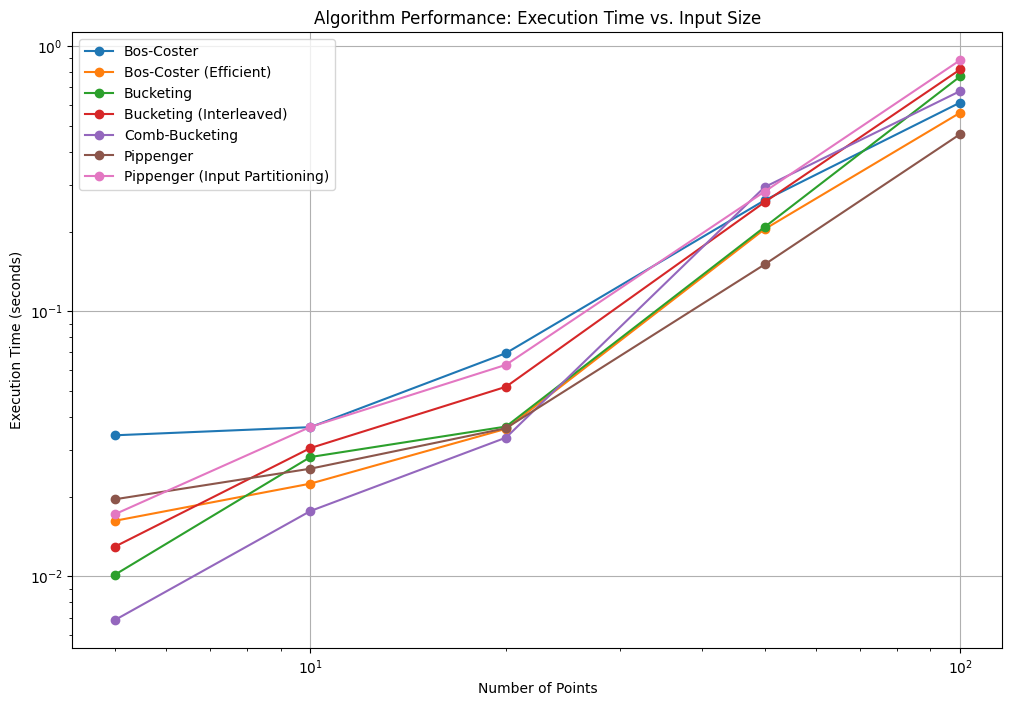

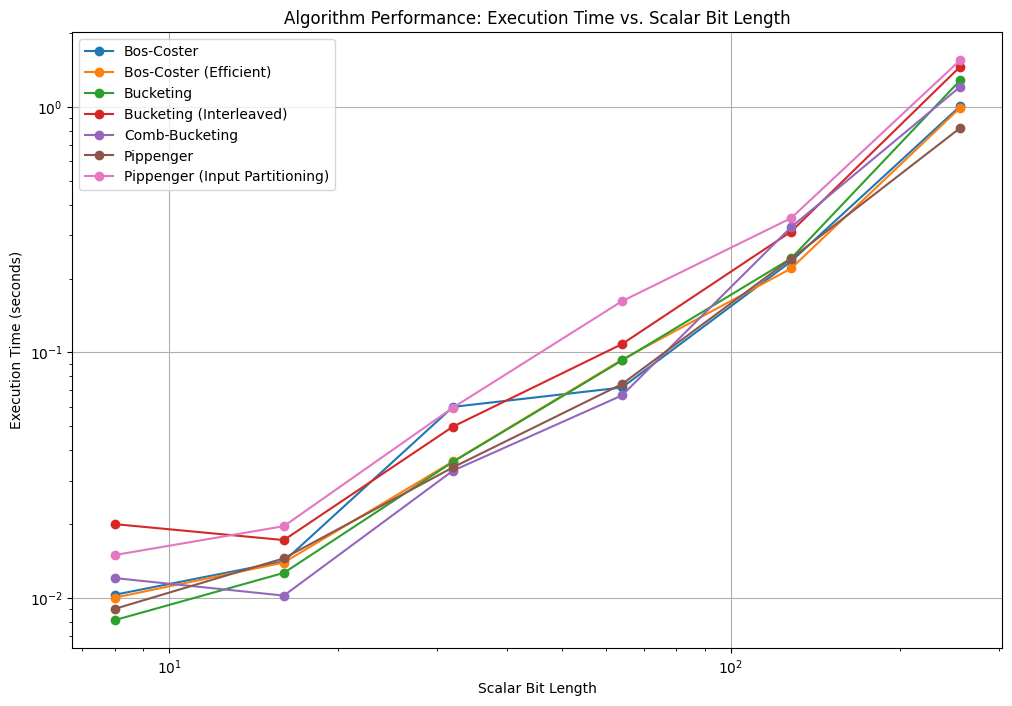

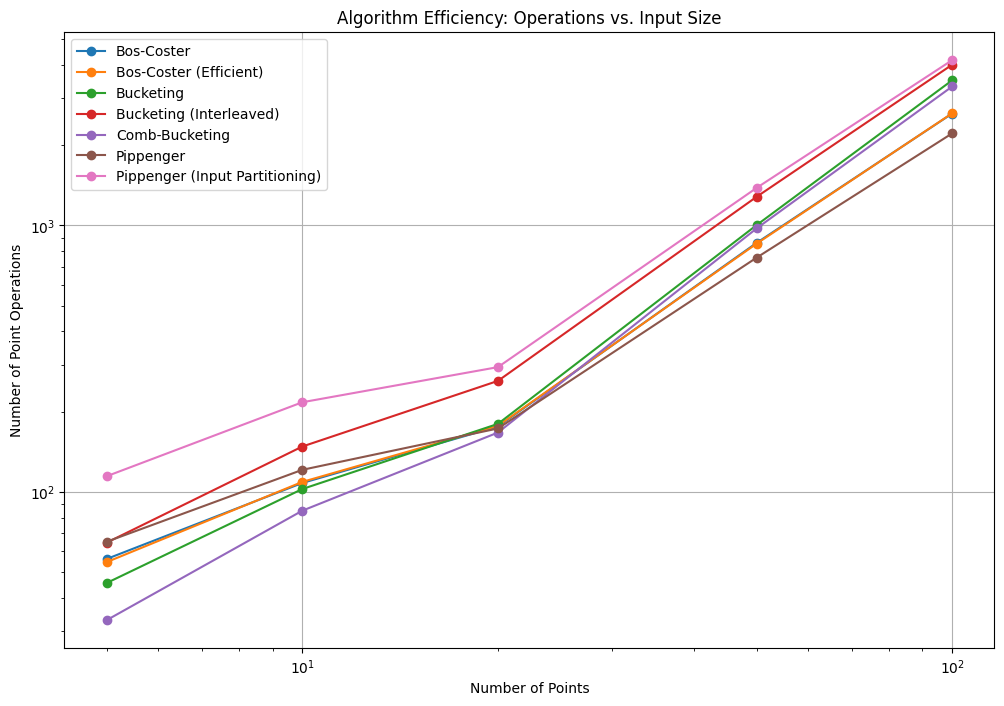

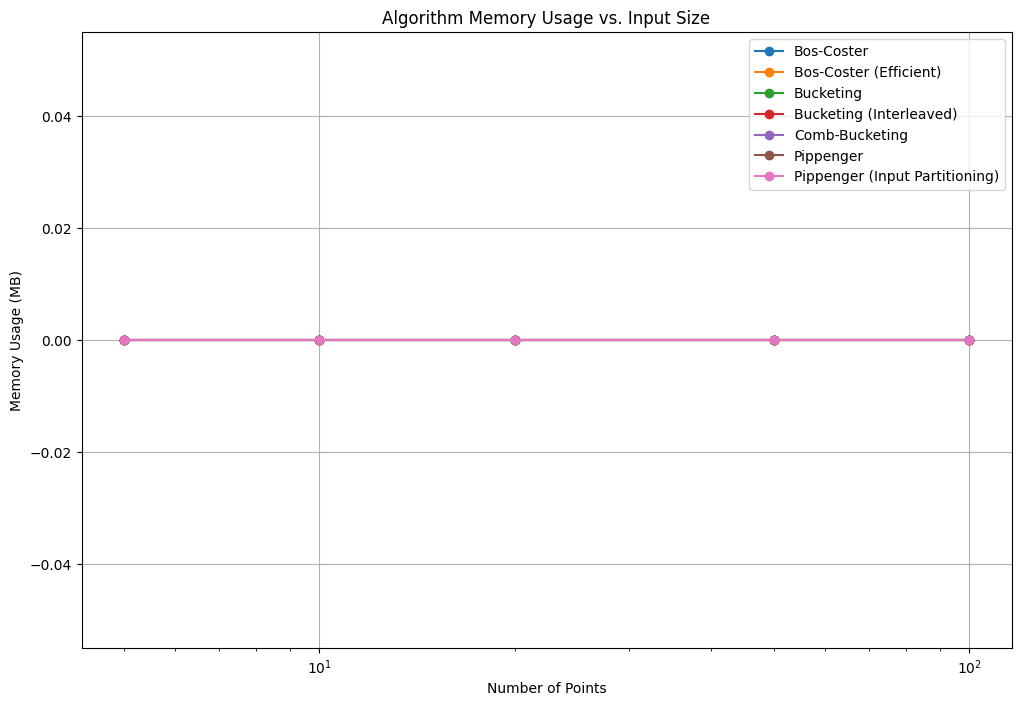

<Figure size 1500x1000 with 0 Axes>

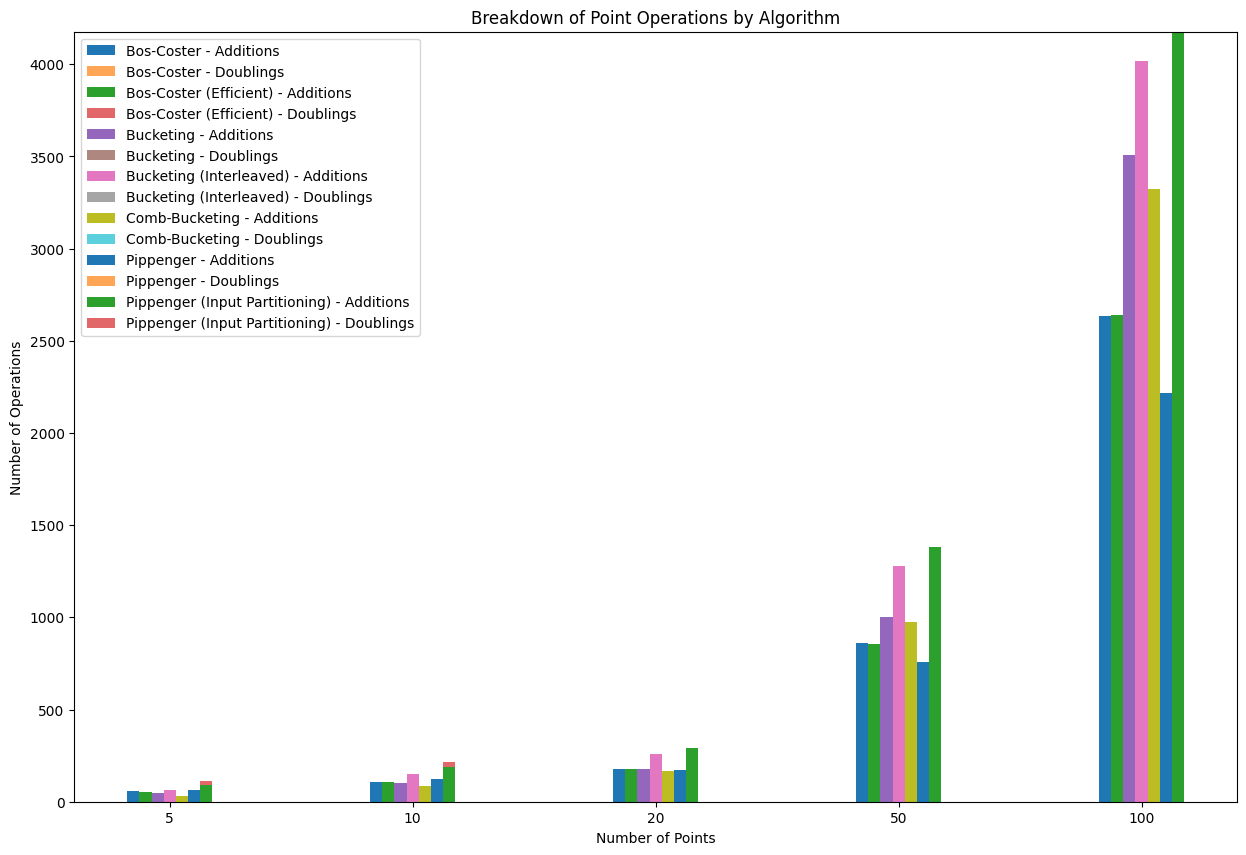

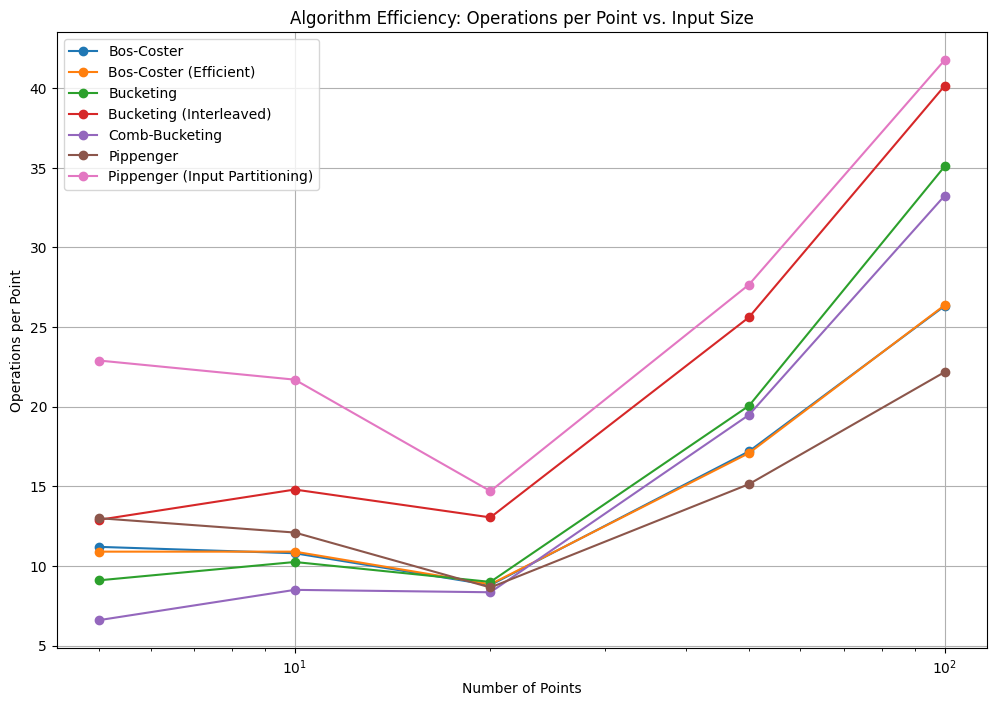

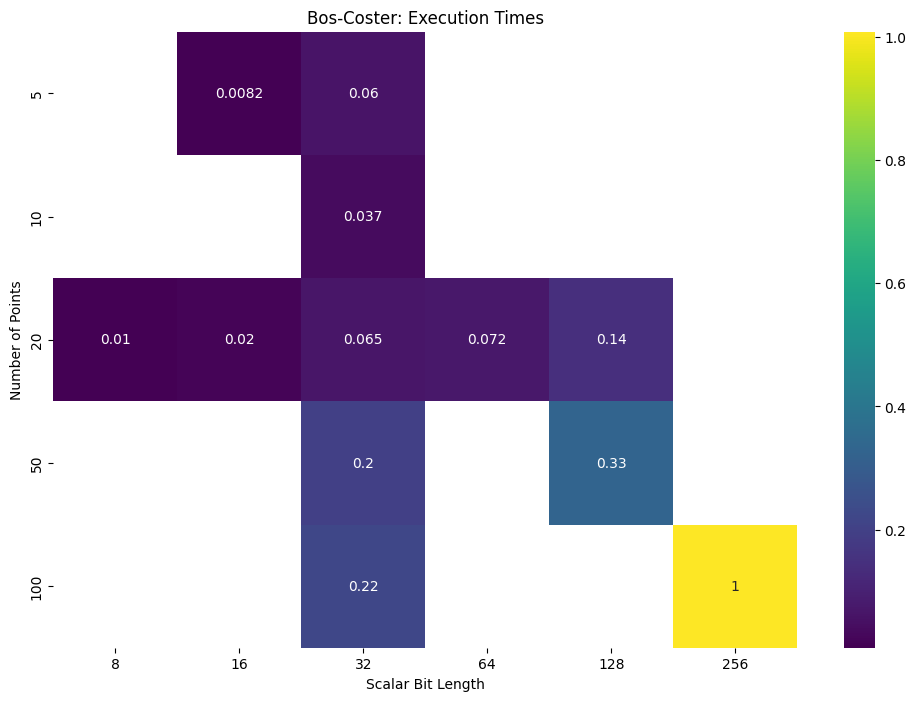

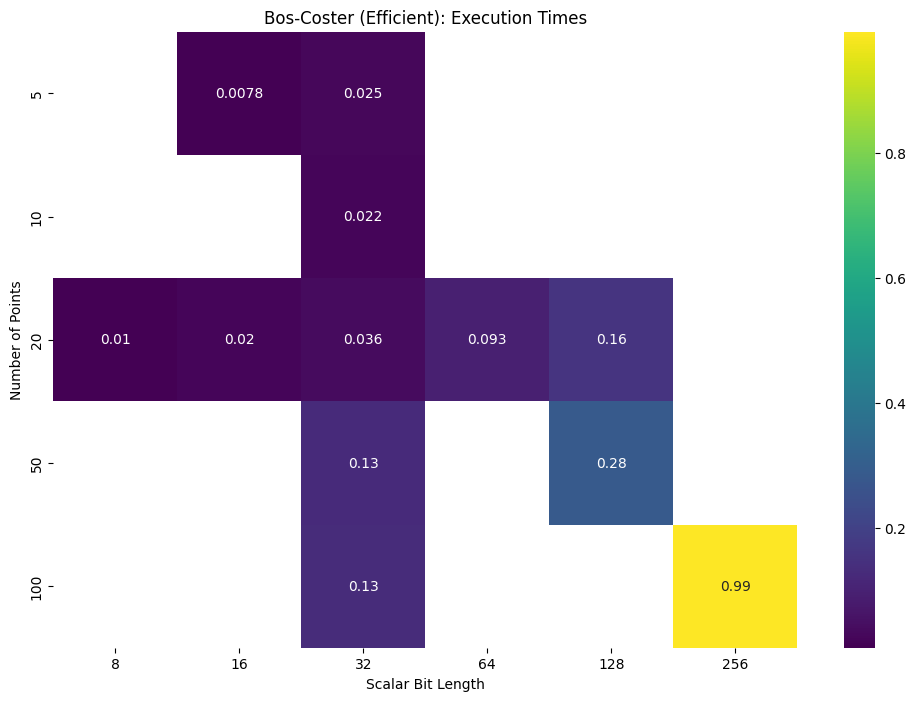

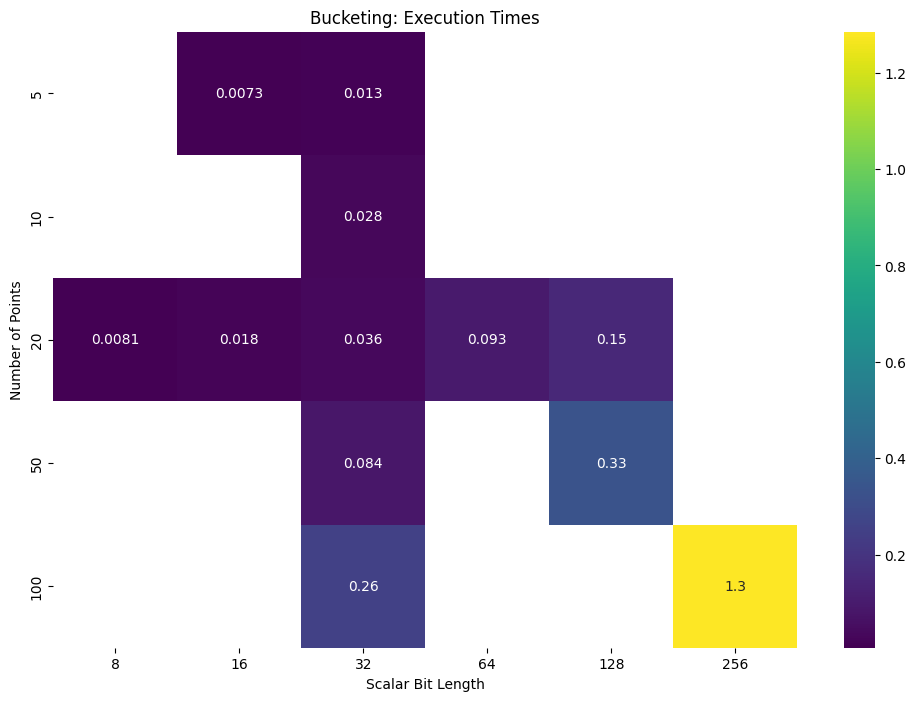

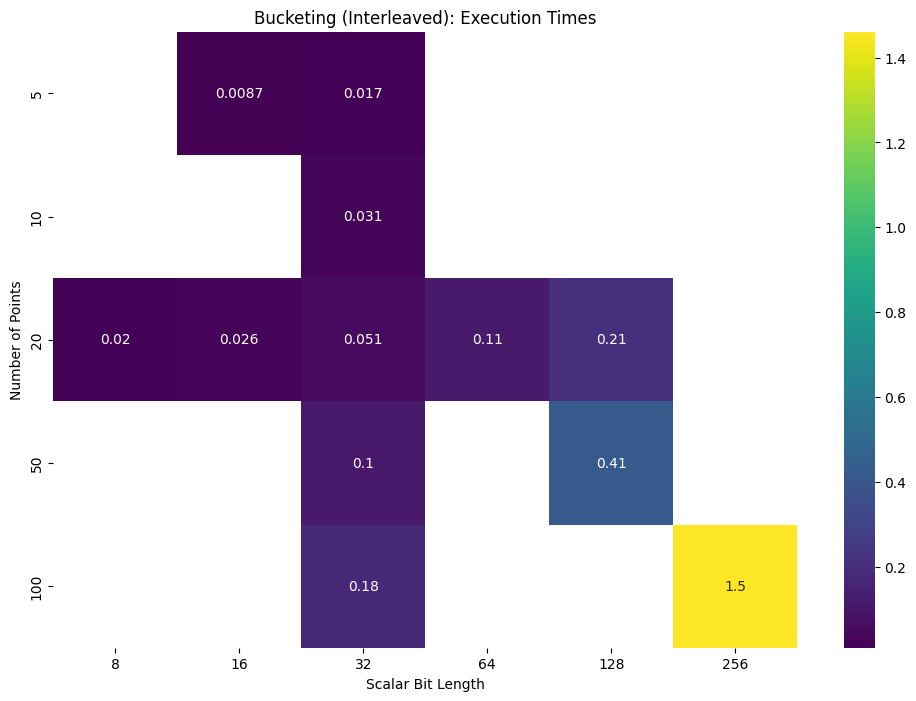

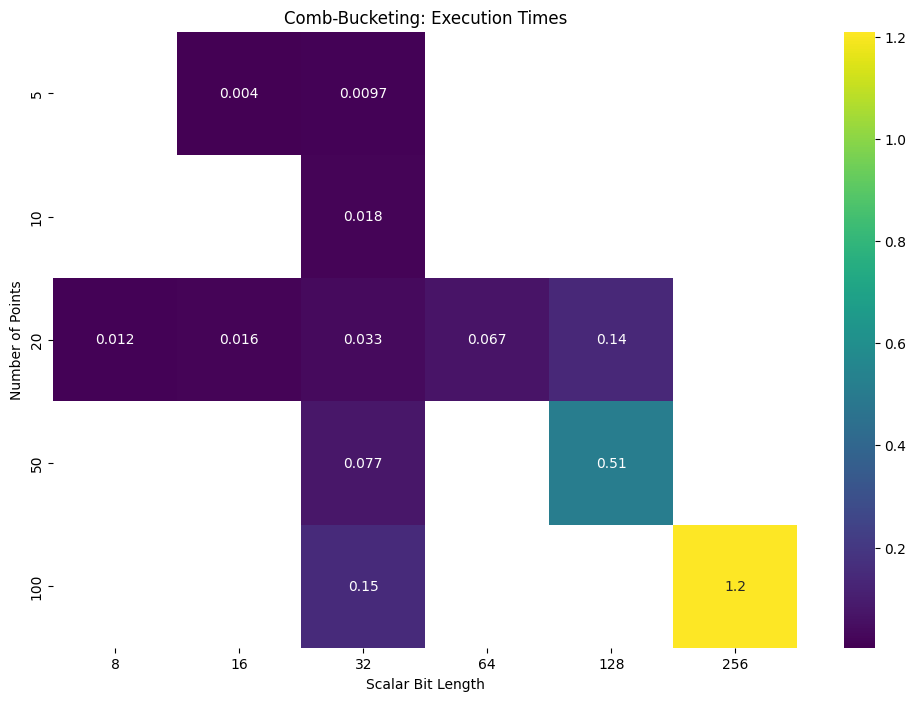

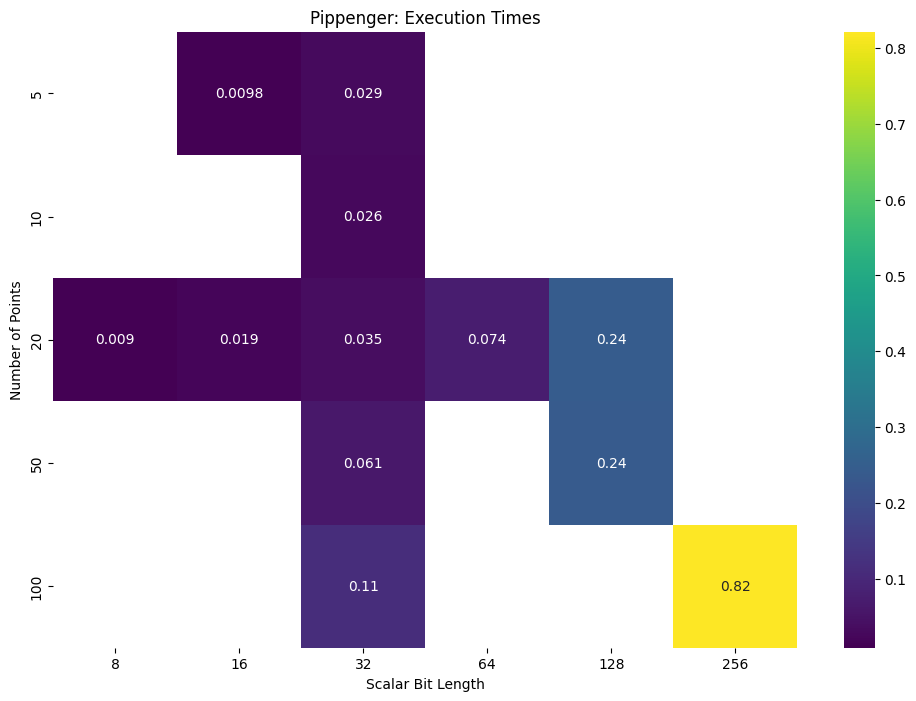

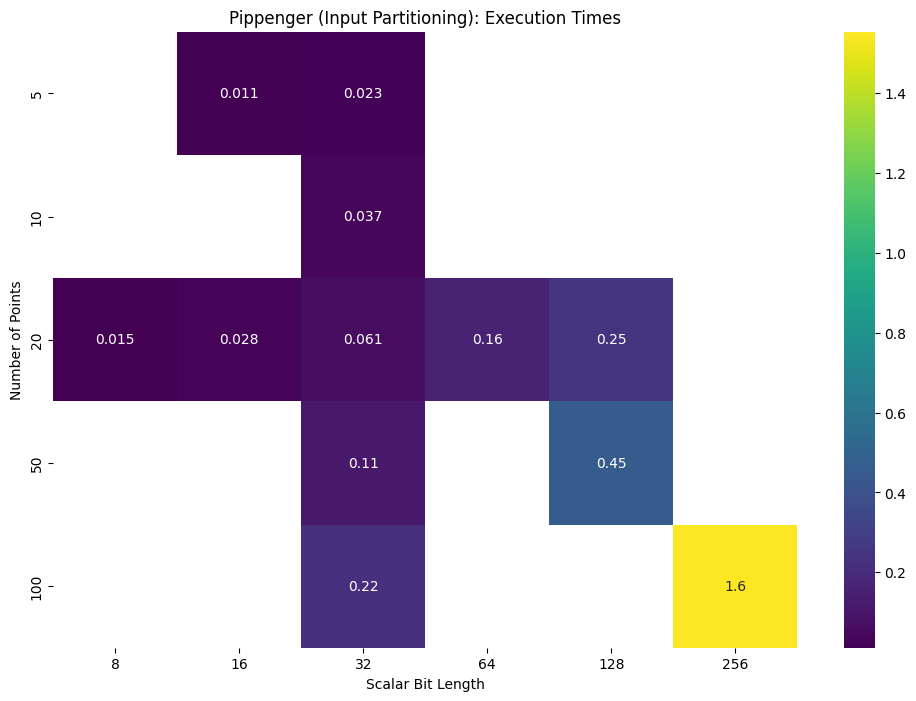

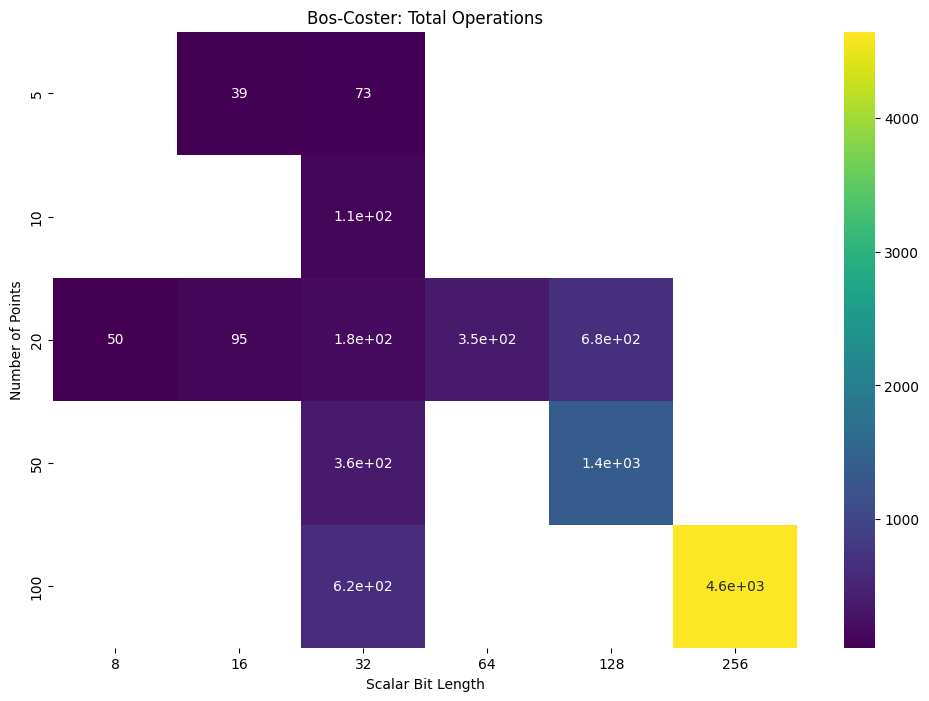

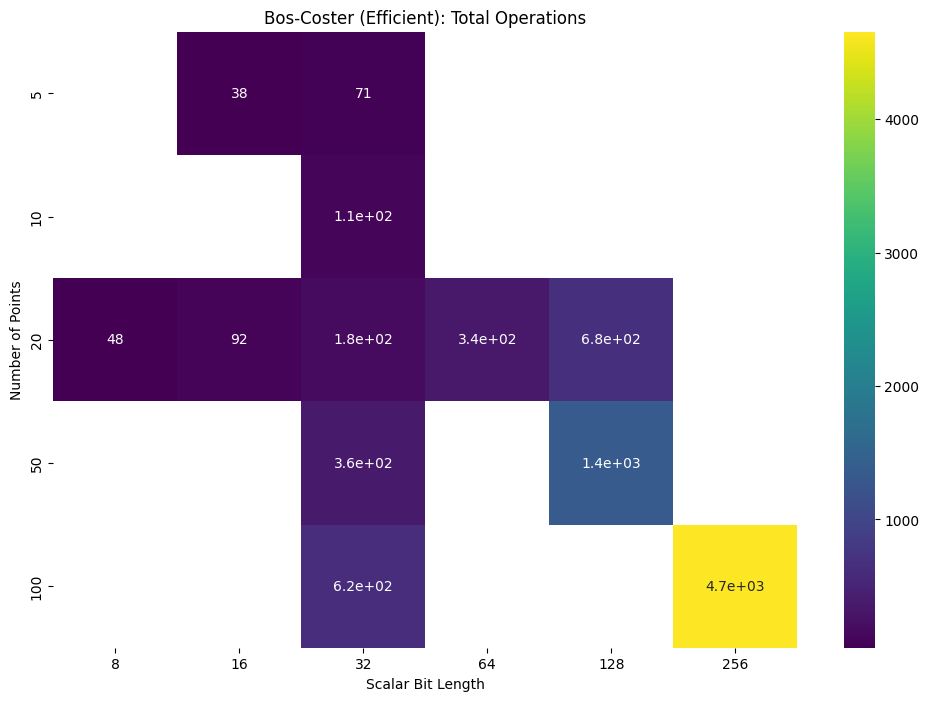

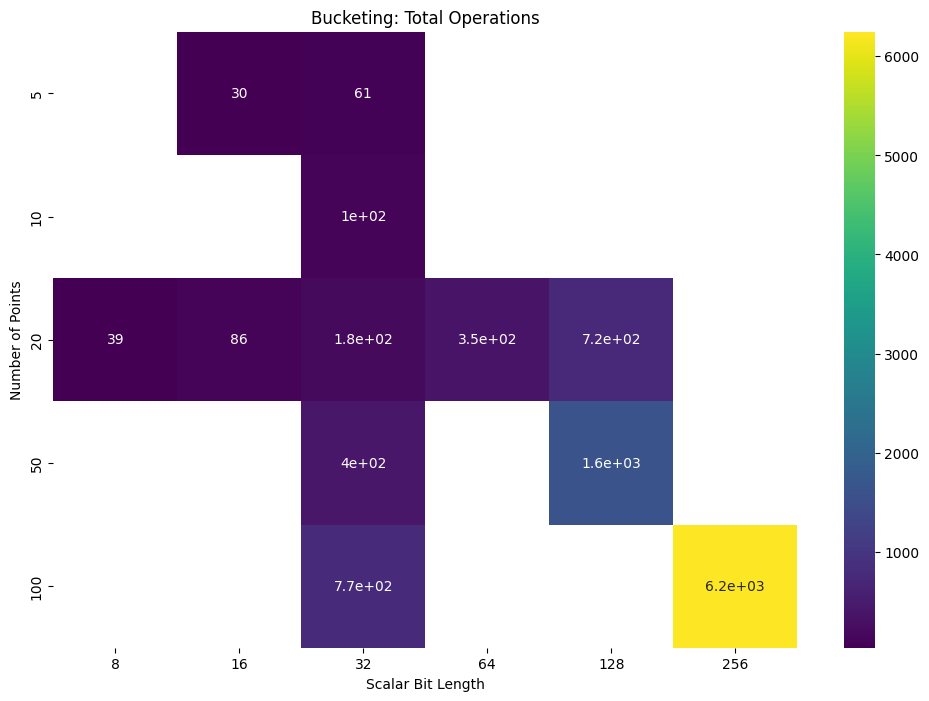

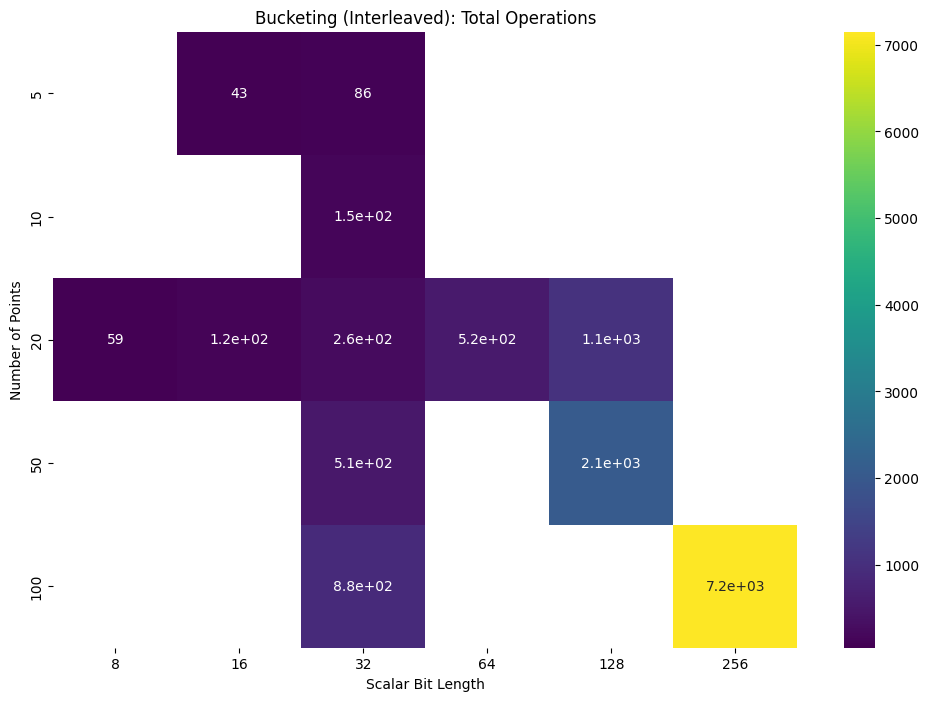

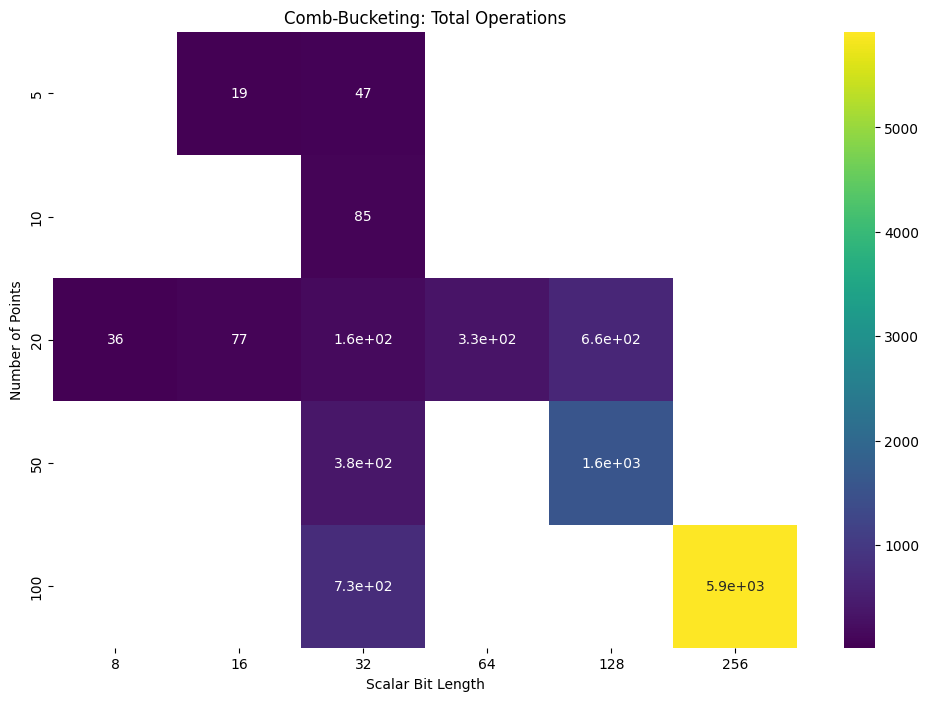

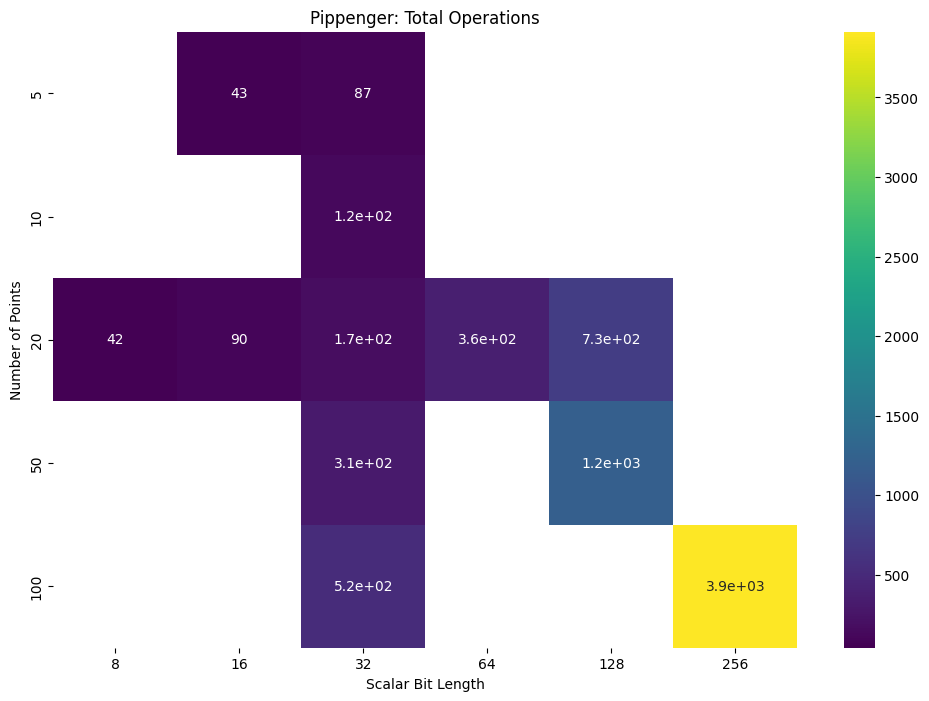

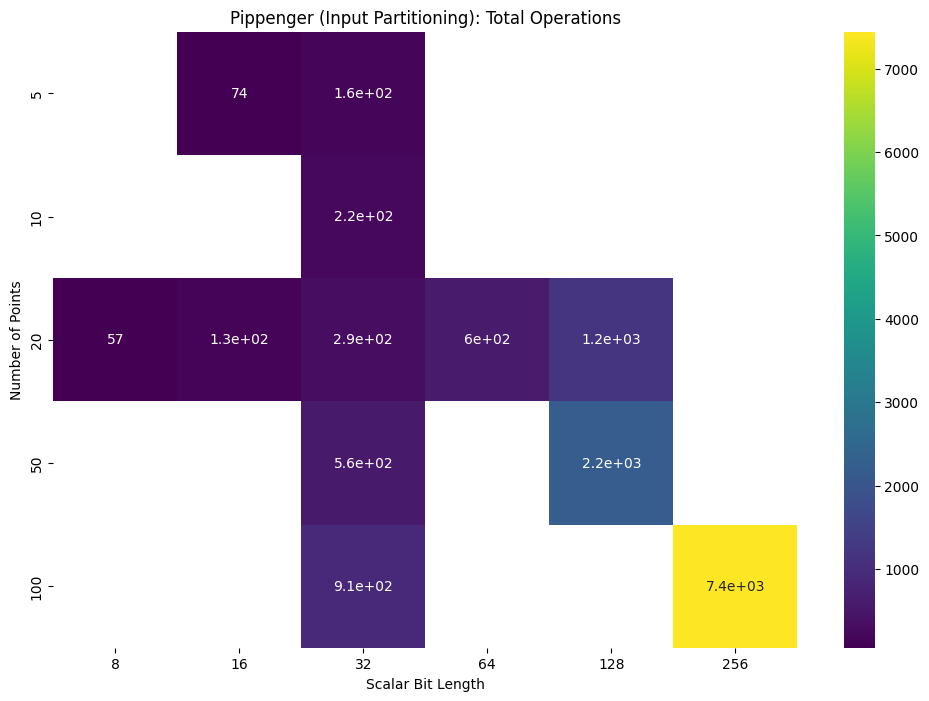

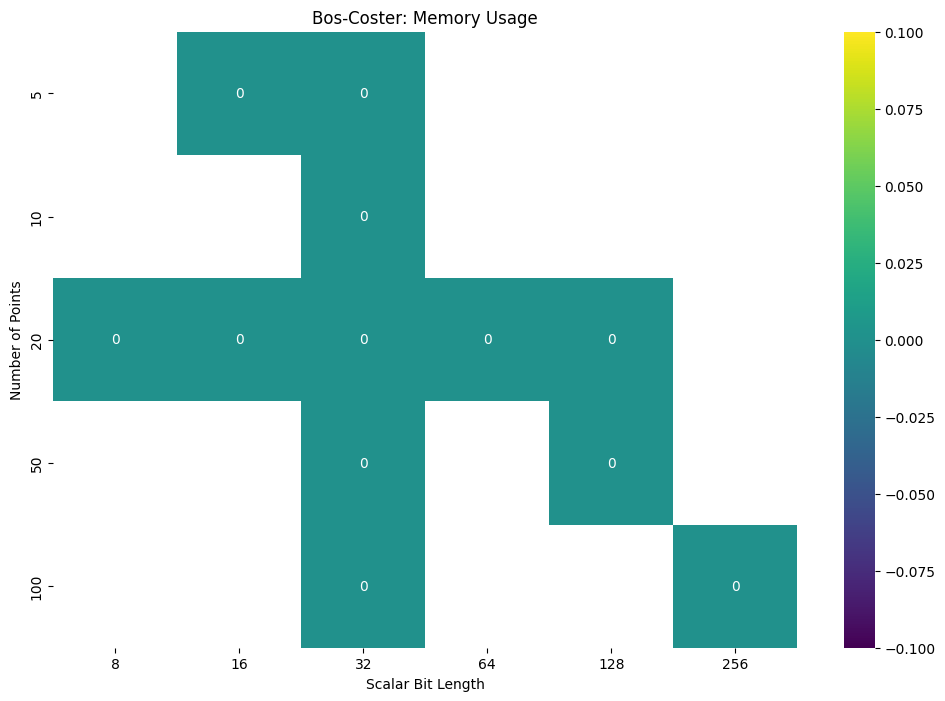

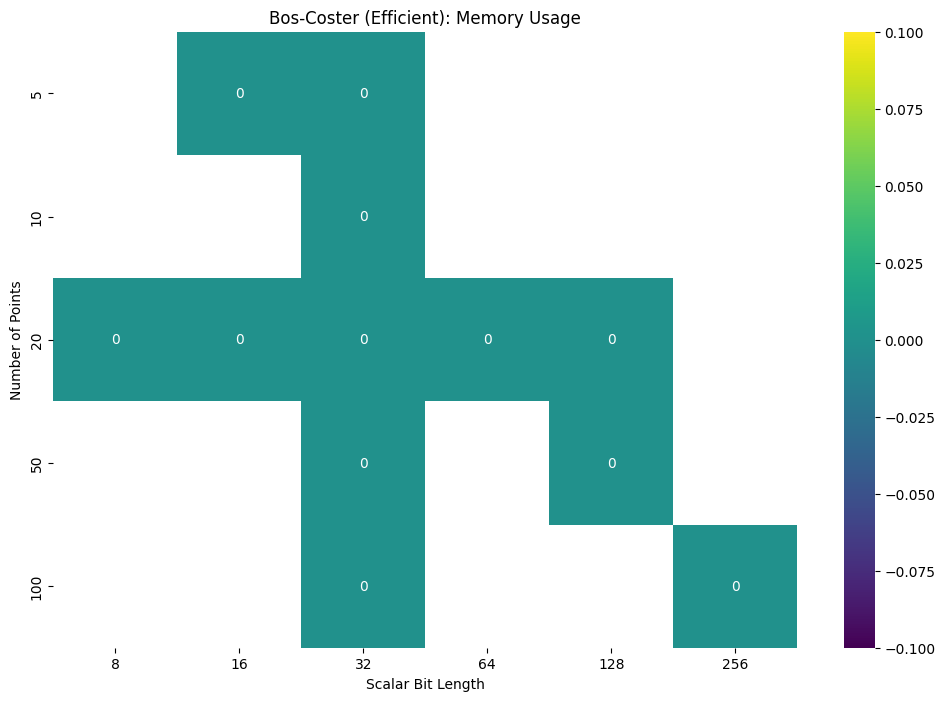

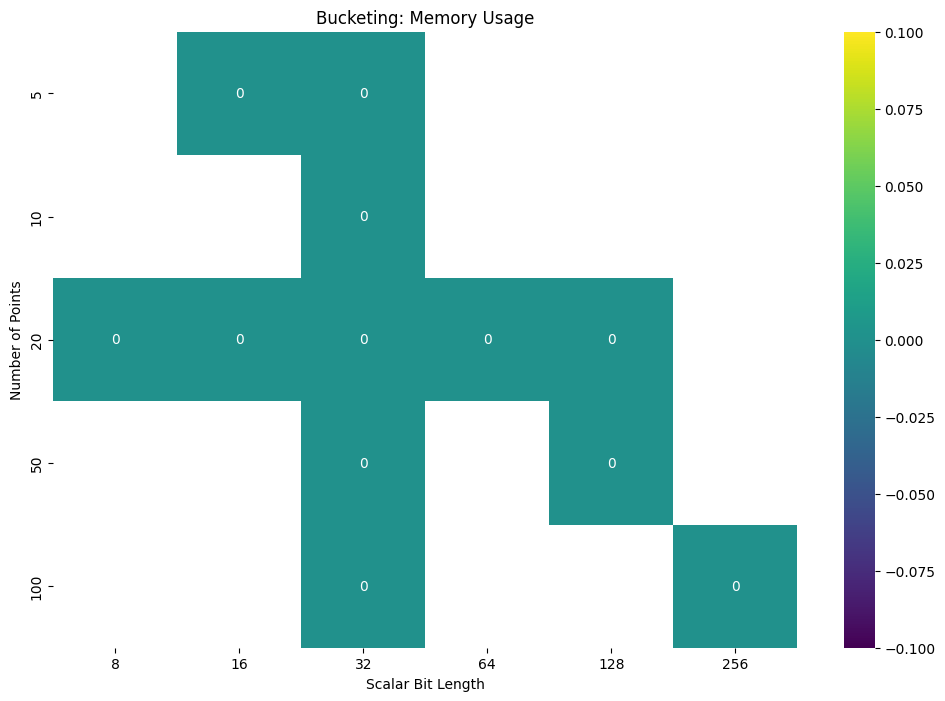

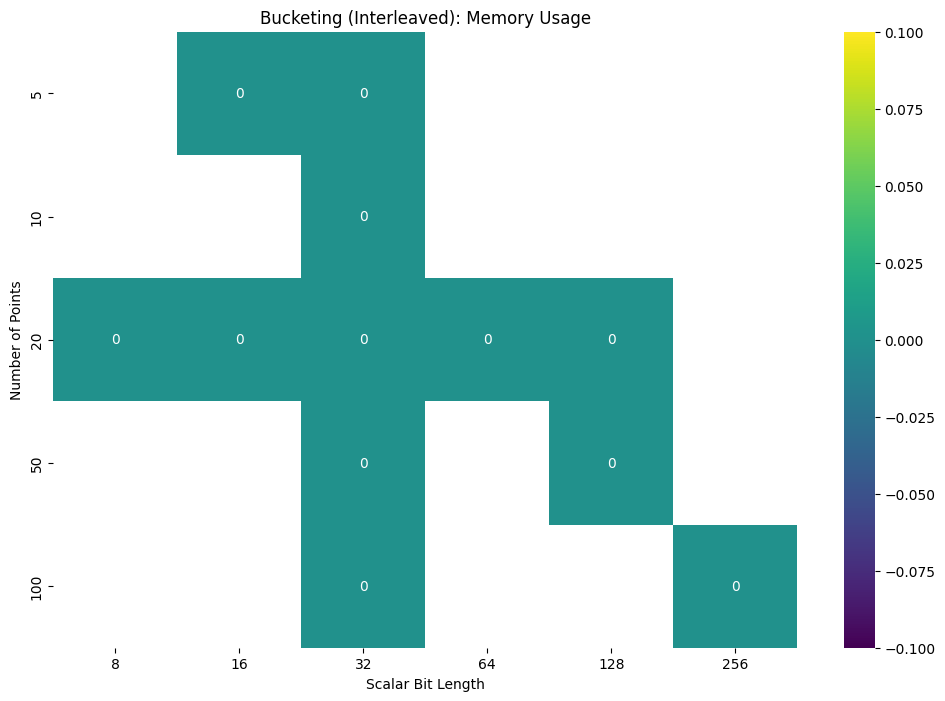

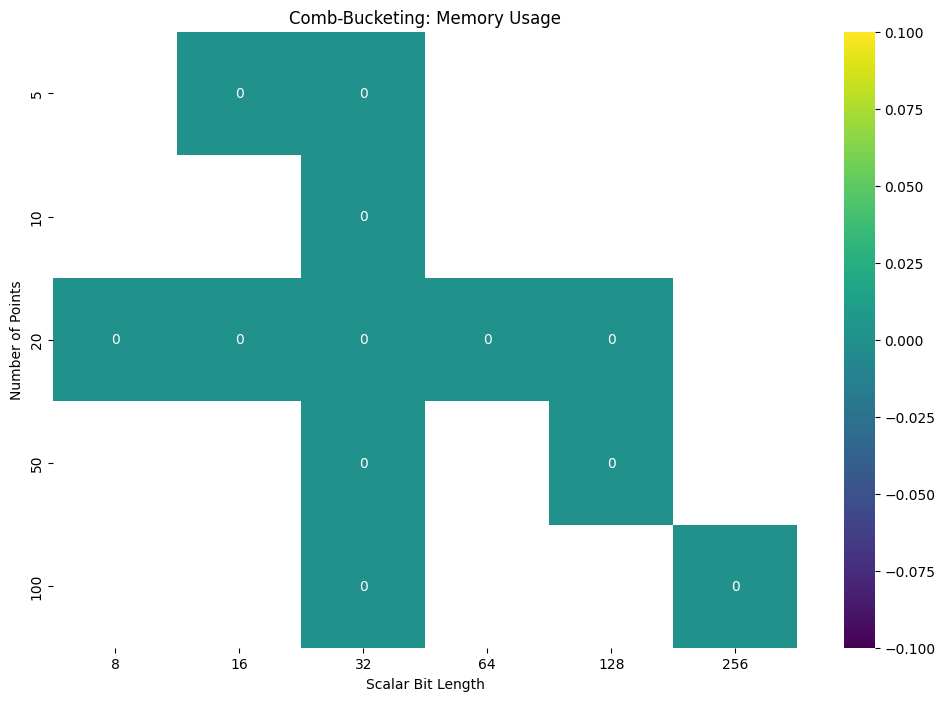

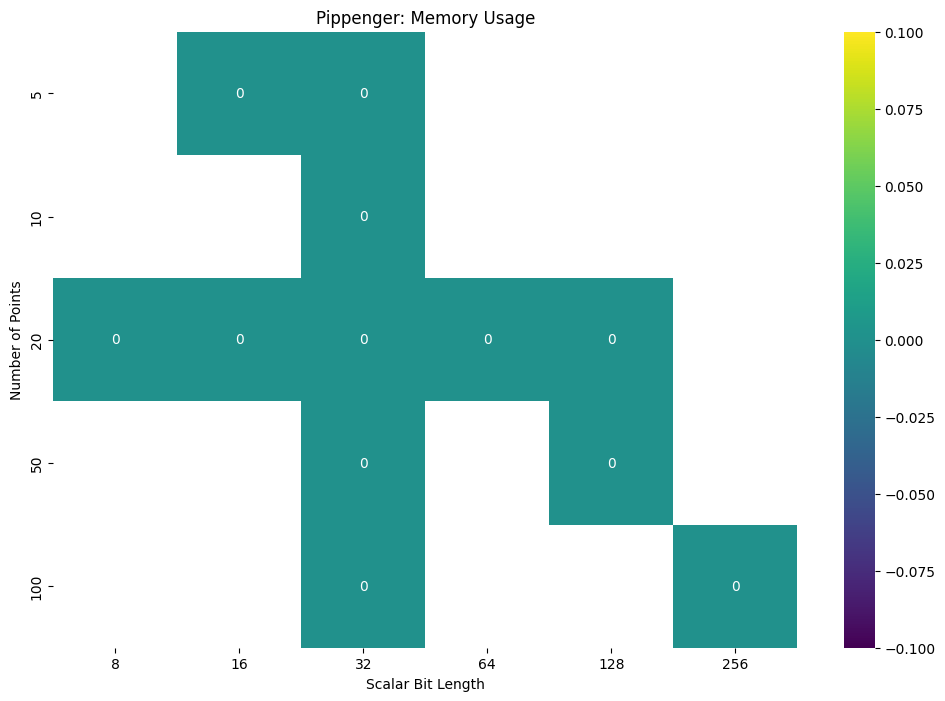

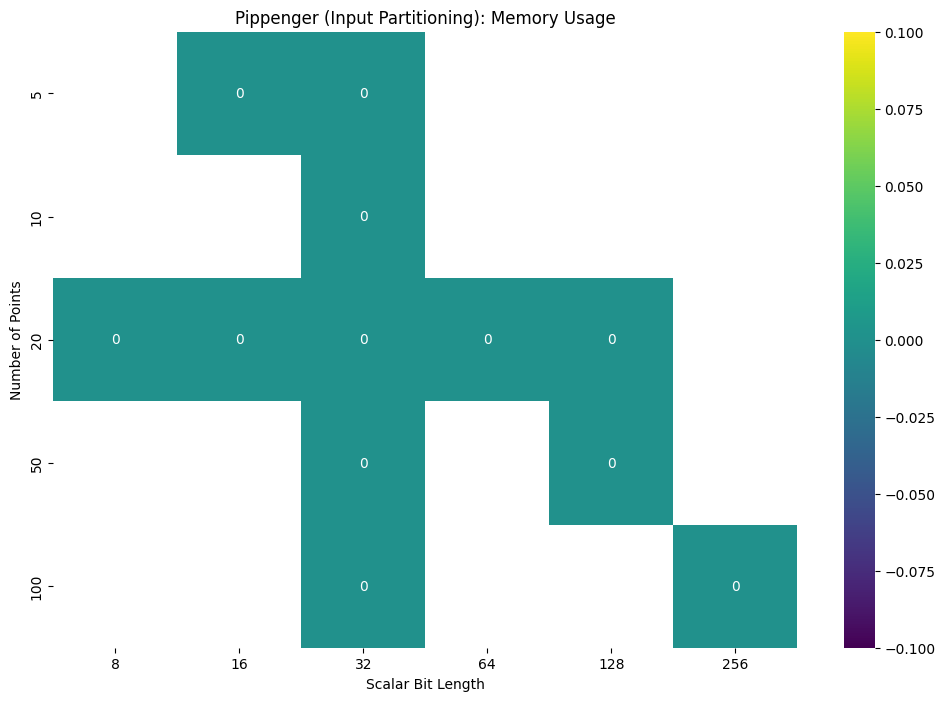

Comprehensive analysis completed and saved to results/comprehensive_analysis.txt
Done!


<ipython-input-17-ec9a12ed6d2e>:1103: RuntimeWarning: divide by zero encountered in log
  log_memory = np.log(median_memory)


In [17]:
import time
import math
import random
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from collections import defaultdict
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MaxNLocator
import statistics
import csv
import gc
import psutil
import os
from memory_profiler import profile
from functools import wraps
from ecpy.curves import Curve, Point

"""
Utility Functions for Multi-Scalar Multiplication Algorithms Comparison
"""

def get_curve(name="secp256k1"):
    """
    Get a predefined curve by name.
    """
    return Curve.get_curve(name)

def random_scalar(order, bits=None):
    """
    Generate a random scalar modulo the curve order.
    """
    if bits is None:
        return random.randint(1, order - 1)
    else:
        return random.randint(1, min(order - 1, 2**bits - 1))

def generate_test_case(curve, n, scalar_bits=None):
    """
    Generate a random test case with n points and n scalars.
    """
    G = curve.generator
    order = curve.order

    # Generate random points by multiplying the generator by random scalars
    points = []
    for _ in range(n):
        k = random_scalar(order)
        points.append(G * k)

    # Generate random scalars
    scalars = [random_scalar(order, scalar_bits) for _ in range(n)]

    return scalars, points

def point_operations_counter(count_operations=True):
    """
    Create a context manager to count point operations.
    """
    from contextlib import contextmanager
    import types

    stats = {'additions': 0, 'doublings': 0}

    # Original methods to be patched
    original_add = Point.__add__
    original_mul = Point.__mul__

    def counting_add(self, other):
        if count_operations and other is not None:  # Not adding point at infinity
            stats['additions'] += 1
        return original_add(self, other)

    def counting_mul(self, scalar):
        # Approximate counting of doublings based on bit length
        if count_operations and scalar > 0:
            # Standard double-and-add has roughly this many doublings
            stats['doublings'] += scalar.bit_length() - 1

            # And roughly this many additions (Hamming weight - 1)
            # This is an approximation; actual ECPy implementation might differ
            bin_scalar = bin(scalar)[2:]
            stats['additions'] += bin_scalar.count('1') - 1

        return original_mul(self, scalar)

    @contextmanager
    def patch_context():
        # Apply the patches
        Point.__add__ = counting_add
        Point.__mul__ = counting_mul

        try:
            yield
        finally:
            # Restore original methods
            Point.__add__ = original_add
            Point.__mul__ = original_mul

    return patch_context(), stats

def compute_known_result(scalars, points):
    """
    Compute the correct result for testing/validation using ECPy's built-in operations.
    """
    if not scalars or not points:
        return None  # Point at infinity

    curve = points[0].curve
    result = None  # Point at infinity

    for scalar, point in zip(scalars, points):
        if scalar == 0 or point is None:
            continue

        if result is None:
            result = point * scalar
        else:
            result = result + (point * scalar)

    return result

"""
Bos-Coster algorithm implementation for multi-scalar multiplication
"""

def bos_coster(scalars, points):
    """
    Compute the multi-scalar multiplication using the Bos-Coster algorithm.
    """
    if not scalars or not points:
        return None  # Point at infinity

    if len(scalars) == 1:
        # Single scalar multiplication case
        return points[0] * scalars[0]

    # Filter out zero scalars
    non_zero_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not non_zero_pairs:
        return None  # Point at infinity

    # Sort pairs by scalar value (descending)
    sorted_pairs = sorted(non_zero_pairs, key=lambda pair: pair[0], reverse=True)

    # Continue until we have reduced to a single scalar-point pair
    while len(sorted_pairs) > 1:
        # Take the two largest scalars
        a1, P1 = sorted_pairs[0]
        a2, P2 = sorted_pairs[1]

        # Compute new scalar and point pairs
        if a1 == a2:
            # If scalars are equal, we can just combine points and keep scalar
            P_combined = P1 + P2
            sorted_pairs = sorted_pairs[2:] + [(a1, P_combined)]
        else:
            # Otherwise, reduce the largest scalar and reinsert
            new_a = a1 - a2
            sorted_pairs = sorted_pairs[2:] + [(new_a, P1), (a2, P1 + P2)]

        # Resort the pairs
        sorted_pairs = sorted(sorted_pairs, key=lambda pair: pair[0], reverse=True)

    # We're left with a single pair
    if sorted_pairs:
        final_scalar, final_point = sorted_pairs[0]
        return final_point * final_scalar
    else:
        return None  # Point at infinity

def bos_coster_efficient(scalars, points):
    """
    More efficient implementation of Bos-Coster algorithm that avoids frequent resorting.
    """
    if not scalars or not points:
        return None  # Point at infinity

    # Filter out zero scalars
    scalar_point_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not scalar_point_pairs:
        return None  # Point at infinity

    # Sort pairs by scalar value (descending)
    heap = sorted(scalar_point_pairs, key=lambda pair: pair[0], reverse=True)

    while len(heap) > 1:
        # Take the two largest scalars
        a1, P1 = heap[0]
        a2, P2 = heap[1]

        # Remove them from the heap
        heap = heap[2:]

        # Compute P1 + P2 (will be reused)
        P1_plus_P2 = P1 + P2

        if a1 > a2:
            # Insert (a1-a2, P1) in the correct position
            new_a = a1 - a2
            pos = 0
            while pos < len(heap) and heap[pos][0] > new_a:
                pos += 1
            heap.insert(pos, (new_a, P1))

        # Insert (a2, P1+P2) in the correct position
        pos = 0
        while pos < len(heap) and heap[pos][0] > a2:
            pos += 1
        heap.insert(pos, (a2, P1_plus_P2))

    # Process final pair
    if heap:
        final_scalar, final_point = heap[0]
        return final_point * final_scalar
    else:
        return None  # Point at infinity

"""
Bucketing algorithm for multi-scalar multiplication
"""

def bucketing_algorithm(scalars, points, window_size=4):
    """
    Compute multi-scalar multiplication using the bucketing method.
    """
    if not scalars or not points:
        return None  # Point at infinity

    # Filter out zero scalars
    scalar_point_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not scalar_point_pairs:
        return None  # Point at infinity

    # Find the maximum bit length of any scalar
    max_bits = max(s.bit_length() for s, _ in scalar_point_pairs)

    # Initialize result to point at infinity
    result = None

    # Process each window of bits from most significant to least significant
    for i in range((max_bits + window_size - 1) // window_size - 1, -1, -1):
        # Double the result window_size times (if not point at infinity)
        if result is not None:
            for _ in range(window_size):
                result = result + result  # Point doubling in ECPy

        # Create buckets for this window
        buckets = [None] * (2**window_size)  # None represents point at infinity

        # Distribute points to buckets based on scalar bits in current window
        for scalar, point in scalar_point_pairs:
            # Extract bits from current window
            shift = i * window_size
            window_bits = (scalar >> shift) & ((1 << window_size) - 1)

            # Add point to appropriate bucket
            if window_bits > 0:
                if buckets[window_bits] is None:
                    buckets[window_bits] = point
                else:
                    buckets[window_bits] = buckets[window_bits] + point

        # Add all non-empty buckets to the result
        for bucket in buckets[1:]:  # Skip bucket 0 (empty)
            if bucket is not None:
                if result is None:
                    result = bucket
                else:
                    result = result + bucket

    return result

def interleaved_bucketing(scalars, points, window_size=4):
    """
    An improved implementation of the bucketing algorithm with better interleaving.
    """
    if not scalars or not points:
        return None  # Point at infinity

    # Filter out zero scalars
    scalar_point_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not scalar_point_pairs:
        return None  # Point at infinity

    # Find the maximum bit length of any scalar
    max_bits = max(s.bit_length() for s, _ in scalar_point_pairs)

    # Number of windows
    num_windows = (max_bits + window_size - 1) // window_size

    # Precompute all buckets for all windows
    all_buckets = []
    for i in range(num_windows):
        # Create buckets for this window
        buckets = [None] * (2**window_size)  # None represents point at infinity

        # Distribute points to buckets based on scalar bits in current window
        for scalar, point in scalar_point_pairs:
            # Extract bits from current window
            shift = i * window_size
            window_bits = (scalar >> shift) & ((1 << window_size) - 1)

            # Add point to appropriate bucket
            if window_bits > 0:
                if buckets[window_bits] is None:
                    buckets[window_bits] = point
                else:
                    buckets[window_bits] = buckets[window_bits] + point

        all_buckets.append(buckets)

    # Compute final result using Horner's method (from MSB to LSB)
    result = None  # Point at infinity

    for i in range(num_windows - 1, -1, -1):
        # Double the result window_size times (if not point at infinity)
        if result is not None:
            for _ in range(window_size):
                result = result + result  # Point doubling in ECPy

        # Efficiently add contributions from current window:
        # Use the "running sum" technique from right to left to reduce additions
        buckets = all_buckets[i]
        running_sum = None

        for j in range(2**window_size - 1, 0, -1):
            if buckets[j] is not None:
                if running_sum is None:
                    running_sum = buckets[j]
                else:
                    running_sum = running_sum + buckets[j]

                if result is None:
                    result = running_sum
                else:
                    result = result + running_sum

    return result

def comb_bucketing(scalars, points, window_size=4, comb_count=2):
    """
    Comb method combined with bucketing for multi-scalar multiplication.
    """
    if not scalars or not points:
        return None  # Point at infinity

    # Filter out zero scalars
    scalar_point_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not scalar_point_pairs:
        return None  # Point at infinity

    # Find the maximum bit length of any scalar
    max_bits = max(s.bit_length() for s, _ in scalar_point_pairs)

    # Adjust max_bits to a multiple of comb_count
    max_bits = ((max_bits + comb_count - 1) // comb_count) * comb_count

    # The bit positions where we place the "teeth" of the comb
    positions = [j * (max_bits // comb_count) for j in range(comb_count)]

    # Initialize result to point at infinity
    result = None

    # Process each window of bits using the comb method
    for i in range((max_bits // comb_count + window_size - 1) // window_size - 1, -1, -1):
        # Double the result window_size times (if not point at infinity)
        if result is not None:
            for _ in range(window_size):
                result = result + result

        # Create buckets for this window
        buckets = [None] * (2**(window_size * comb_count))

        # Distribute points to buckets based on scalar bits in current window
        for scalar, point in scalar_point_pairs:
            # Extract bits from current window across all comb positions
            bucket_index = 0
            for j, pos in enumerate(positions):
                shift = pos + i * window_size
                if shift < max_bits:  # Ensure we don't shift beyond scalar
                    window_bits = (scalar >> shift) & ((1 << window_size) - 1)
                    bucket_index |= window_bits << (j * window_size)

            # Add point to appropriate bucket
            if bucket_index > 0:
                if buckets[bucket_index] is None:
                    buckets[bucket_index] = point
                else:
                    buckets[bucket_index] = buckets[bucket_index] + point

        # Add all non-empty buckets to the result
        running_sum = None
        for j in range(len(buckets) - 1, 0, -1):
            if buckets[j] is not None:
                if running_sum is None:
                    running_sum = buckets[j]
                else:
                    running_sum = running_sum + buckets[j]

                if result is None:
                    result = running_sum
                else:
                    result = result + running_sum

    return result

"""
Pippenger's algorithm for multi-scalar multiplication
"""

def pippenger_algorithm(scalars, points, c=None):
    """
    Compute multi-scalar multiplication using Pippenger's algorithm.
    """
    if not scalars or not points:
        return None  # Point at infinity

    n = len(scalars)
    if n == 0:
        return None

    # Filter out zero scalars
    scalar_point_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not scalar_point_pairs:
        return None  # Point at infinity

    filtered_scalars = [pair[0] for pair in scalar_point_pairs]
    filtered_points = [pair[1] for pair in scalar_point_pairs]

    # If only one point remains, use regular scalar multiplication
    if len(filtered_scalars) == 1:
        return filtered_points[0] * filtered_scalars[0]

    # Determine parameter c if not provided
    # This controls the number of bits processed at once
    if c is None:
        # Following Ryan Henry's paper recommendations
        c = max(2, round(math.log2(n)))

    # Find the maximum bit length
    max_bits = max(s.bit_length() for s in filtered_scalars)

    # Apply Pippenger's algorithm
    return _pippenger_recursive(filtered_scalars, filtered_points, max_bits, c)

def _pippenger_recursive(scalars, points, max_bits, c, level=0):
    """
    Recursive implementation of Pippenger's algorithm.
    """
    n = len(scalars)

    # Base case: single scalar multiplication
    if n == 1:
        return points[0] * scalars[0]

    # Base case: if bit length is small enough, use naive method
    if max_bits <= c:
        return _naive_msm(scalars, points)

    # Divide scalars into chunks of c bits
    h = (max_bits + c - 1) // c  # Ceiling division

    # Initialise result
    result = None

    # Process from most significant to least significant chunk
    for i in range(h - 1, -1, -1):
        # Double the result c times
        if result is not None:
            for _ in range(c):
                result = result + result

        # Group points by their scalar's bits in the current window
        buckets = {}

        for j, (scalar, point) in enumerate(zip(scalars, points)):
            # Extract c bits at position i*c
            shift = i * c
            chunk = (scalar >> shift) & ((1 << c) - 1)

            if chunk > 0:
                if chunk in buckets:
                    buckets[chunk].append((j, point))
                else:
                    buckets[chunk] = [(j, point)]

        # Process each non-empty bucket
        for chunk, bucket_points in buckets.items():
            # Sum all points in this bucket
            bucket_sum = None
            for _, point in bucket_points:
                if bucket_sum is None:
                    bucket_sum = point
                else:
                    bucket_sum = bucket_sum + point

            # Add to result with appropriate weight
            if result is None:
                result = bucket_sum
            else:
                result = result + bucket_sum

    return result

def _naive_msm(scalars, points):
    """
    Naive implementation of multi-scalar multiplication.
    """
    result = None
    for scalar, point in zip(scalars, points):
        temp = point * scalar
        if result is None:
            result = temp
        else:
            result = result + temp
    return result

def pippenger_input_partitioning(scalars, points, chunk_size=None):
    """
    Implementation of Pippenger's algorithm using the input partitioning approach.
    """
    if not scalars or not points:
        return None  # Point at infinity

    n = len(scalars)
    if n == 0:
        return None

    # Filter out zero scalars
    scalar_point_pairs = [(s, p) for s, p in zip(scalars, points) if s != 0]
    if not scalar_point_pairs:
        return None  # Point at infinity

    filtered_scalars = [pair[0] for pair in scalar_point_pairs]
    filtered_points = [pair[1] for pair in scalar_point_pairs]
    n = len(filtered_scalars)

    # If only one point remains, use regular scalar multiplication
    if n == 1:
        return filtered_points[0] * filtered_scalars[0]

    # Determine chunk size if not provided
    if chunk_size is None:
        # Following recommendations from the papers
        chunk_size = max(2, round(math.log2(n)))

    # Partition the input points into chunks
    num_chunks = (n + chunk_size - 1) // chunk_size

    # Process each chunk and accumulate results
    result = None

    for i in range(num_chunks):
        start = i * chunk_size
        end = min(start + chunk_size, n)

        chunk_scalars = filtered_scalars[start:end]
        chunk_points = filtered_points[start:end]

        # Recursively solve the subproblem for this chunk
        if len(chunk_scalars) == 1:
            # Base case: single scalar multiplication
            chunk_result = chunk_points[0] * chunk_scalars[0]
        else:
            # Recursive case: solve the subproblem
            chunk_result = pippenger_algorithm(chunk_scalars, chunk_points, c=chunk_size)

        # Combine with the overall result
        if result is None:
            result = chunk_result
        else:
            result = result + chunk_result

    return result

"""
Benchmarking Functions
"""

def measure_time(func, *args, **kwargs):
    """Measure execution time of a function"""
    gc.collect()  # Force garbage collection before timing
    start_time = time.time()
    result = func(*args, **kwargs)
    end_time = time.time()
    return result, end_time - start_time

def measure_memory_usage(func, *args, **kwargs):
    """Measure peak memory usage of a function"""
    # Get process
    process = psutil.Process(os.getpid())

    # Record memory before
    gc.collect()
    memory_before = process.memory_info().rss / 1024 / 1024  # Convert to MB

    # Run function
    result = func(*args, **kwargs)

    # Record memory after
    gc.collect()
    memory_after = process.memory_info().rss / 1024 / 1024  # Convert to MB

    return result, memory_after - memory_before

def count_operations(func, scalars, points):
    """Count the number of point operations"""
    patch_context, stats = point_operations_counter()
    with patch_context:
        result = func(scalars, points)
    return result, stats

def benchmark_algorithm(algorithm_func, test_cases, curve_name="secp256k1", trials=3):
    """
    Benchmark an algorithm on multiple test cases, with multiple trials.

    Returns:
        dict: Various metrics for the algorithm performance
    """
    curve = get_curve(curve_name)
    results = {
        'execution_times': [],
        'memory_usage': [],
        'point_additions': [],
        'point_doublings': [],
        'total_operations': [],
        'input_sizes': [],
        'scalar_bit_lengths': []
    }

    for n, bits in test_cases:
        # Generate test case
        scalars, points = generate_test_case(curve, n, bits)

        # Store input characteristics
        results['input_sizes'].append(n)
        results['scalar_bit_lengths'].append(bits)

        # Multiple trials for more accurate timing
        trial_times = []
        trial_memory = []

        for _ in range(trials):
            # Measure execution time
            _, execution_time = measure_time(algorithm_func, scalars, points)
            trial_times.append(execution_time)

            # Measure memory usage
            _, memory_usage = measure_memory_usage(algorithm_func, scalars, points)
            trial_memory.append(memory_usage)

        # Store median time and memory usage
        results['execution_times'].append(statistics.median(trial_times))
        results['memory_usage'].append(statistics.median(trial_memory))

        # Count operations (just once, as it should be deterministic)
        _, operation_stats = count_operations(algorithm_func, scalars, points)
        results['point_additions'].append(operation_stats['additions'])
        results['point_doublings'].append(operation_stats['doublings'])
        results['total_operations'].append(operation_stats['additions'] + operation_stats['doublings'])

    return results

def compare_algorithms(algorithms, test_cases, curve_name="secp256k1", trials=3):
    """
    Compare multiple algorithms on the same test cases.

    Args:
        algorithms: Dict mapping algorithm names to functions
        test_cases: List of (n, bits) tuples defining test cases
        curve_name: Name of the elliptic curve to use
        trials: Number of trials for timing

    Returns:
        dict: Benchmark results for each algorithm
    """
    results = {}

    for name, func in algorithms.items():
        print(f"Benchmarking {name}...")
        algorithm_results = benchmark_algorithm(func, test_cases, curve_name, trials)
        results[name] = algorithm_results

    return results

"""
Visualization Functions
"""

def plot_execution_time_vs_size(results, save_path=None):
    """Plot execution time vs. input size for all algorithms"""
    plt.figure(figsize=(12, 8))

    for algo_name, algo_results in results.items():
        sizes = algo_results['input_sizes']
        times = algo_results['execution_times']

        # Group by size (in case there are multiple bit lengths for the same size)
        size_to_times = defaultdict(list)
        for size, time in zip(sizes, times):
            size_to_times[size].append(time)

        # Calculate median time for each size
        unique_sizes = sorted(size_to_times.keys())
        median_times = [statistics.median(size_to_times[size]) for size in unique_sizes]

        plt.plot(unique_sizes, median_times, marker='o', label=algo_name)

    plt.xlabel('Number of Points')
    plt.ylabel('Execution Time (seconds)')
    plt.title('Algorithm Performance: Execution Time vs. Input Size')
    plt.legend()
    plt.grid(True)
    plt.xscale('log')
    plt.yscale('log')

    if save_path:
        plt.savefig(save_path)

    plt.show()

def plot_execution_time_vs_bits(results, save_path=None):
    """Plot execution time vs. scalar bit length for all algorithms"""
    plt.figure(figsize=(12, 8))

    for algo_name, algo_results in results.items():
        bits = algo_results['scalar_bit_lengths']
        times = algo_results['execution_times']

        # Group by bit length
        bits_to_times = defaultdict(list)
        for bit_length, time in zip(bits, times):
            bits_to_times[bit_length].append(time)

        # Calculate median time for each bit length
        unique_bits = sorted(bits_to_times.keys())
        median_times = [statistics.median(bits_to_times[bit]) for bit in unique_bits]

        plt.plot(unique_bits, median_times, marker='o', label=algo_name)

    plt.xlabel('Scalar Bit Length')
    plt.ylabel('Execution Time (seconds)')
    plt.title('Algorithm Performance: Execution Time vs. Scalar Bit Length')
    plt.legend()
    plt.grid(True)
    plt.xscale('log')
    plt.yscale('log')

    if save_path:
        plt.savefig(save_path)

    plt.show()

def plot_operations_vs_size(results, save_path=None):
    """Plot number of operations vs. input size for all algorithms"""
    plt.figure(figsize=(12, 8))

    for algo_name, algo_results in results.items():
        sizes = algo_results['input_sizes']
        ops = algo_results['total_operations']

        # Group by size
        size_to_ops = defaultdict(list)
        for size, op in zip(sizes, ops):
            size_to_ops[size].append(op)

        # Calculate median ops for each size
        unique_sizes = sorted(size_to_ops.keys())
        median_ops = [statistics.median(size_to_ops[size]) for size in unique_sizes]

        plt.plot(unique_sizes, median_ops, marker='o', label=algo_name)

    plt.xlabel('Number of Points')
    plt.ylabel('Number of Point Operations')
    plt.title('Algorithm Efficiency: Operations vs. Input Size')
    plt.legend()
    plt.grid(True)
    plt.xscale('log')
    plt.yscale('log')

    if save_path:
        plt.savefig(save_path)

    plt.show()

def plot_memory_usage(results, save_path=None):
    """Plot memory usage vs. input size for all algorithms"""
    plt.figure(figsize=(12, 8))

    for algo_name, algo_results in results.items():
        sizes = algo_results['input_sizes']
        memory = algo_results['memory_usage']

        # Group by size
        size_to_memory = defaultdict(list)
        for size, mem in zip(sizes, memory):
            size_to_memory[size].append(mem)

        # Calculate median memory for each size
        unique_sizes = sorted(size_to_memory.keys())
        median_memory = [statistics.median(size_to_memory[size]) for size in unique_sizes]

        plt.plot(unique_sizes, median_memory, marker='o', label=algo_name)

    plt.xlabel('Number of Points')
    plt.ylabel('Memory Usage (MB)')
    plt.title('Algorithm Memory Usage vs. Input Size')
    plt.legend()
    plt.grid(True)
    plt.xscale('log')

    if save_path:
        plt.savefig(save_path)

    plt.show()

def plot_operations_breakdown(results, save_path=None):
    """Plot breakdown of operations (additions vs. doublings) for all algorithms"""
    plt.figure(figsize=(15, 10))

    algorithms = list(results.keys())
    n_algos = len(algorithms)

    # Get unique input sizes
    all_sizes = []
    for algo_results in results.values():
        all_sizes.extend(algo_results['input_sizes'])
    unique_sizes = sorted(set(all_sizes))

    # For each algorithm, get the median number of additions and doublings for each input size
    additions_data = []
    doublings_data = []

    for algo_name in algorithms:
        algo_results = results[algo_name]

        # Group by size
        size_to_adds = defaultdict(list)
        size_to_doubles = defaultdict(list)

        for size, adds, doubles in zip(
            algo_results['input_sizes'],
            algo_results['point_additions'],
            algo_results['point_doublings']
        ):
            size_to_adds[size].append(adds)
            size_to_doubles[size].append(doubles)

        # Calculate median for each size
        algo_adds = []
        algo_doubles = []

        for size in unique_sizes:
            if size in size_to_adds:
                algo_adds.append(statistics.median(size_to_adds[size]))
                algo_doubles.append(statistics.median(size_to_doubles[size]))
            else:
                algo_adds.append(0)
                algo_doubles.append(0)

        additions_data.append(algo_adds)
        doublings_data.append(algo_doubles)

    # Set up the plot
    x = np.arange(len(unique_sizes))
    width = 0.35 / n_algos

    fig, ax = plt.subplots(figsize=(15, 10))

    # Plot bars for each algorithm
    for i, algo_name in enumerate(algorithms):
        # Plot additions
        ax.bar(x - width*(n_algos-1)/2 + i*width, additions_data[i], width, label=f'{algo_name} - Additions')
        # Plot doublings
        ax.bar(x - width*(n_algos-1)/2 + i*width, doublings_data[i], width, bottom=additions_data[i],
               label=f'{algo_name} - Doublings', alpha=0.7)

    ax.set_xlabel('Number of Points')
    ax.set_ylabel('Number of Operations')
    ax.set_title('Breakdown of Point Operations by Algorithm')
    ax.set_xticks(x)
    ax.set_xticklabels(unique_sizes)
    ax.legend()

    if save_path:
        plt.savefig(save_path)

    plt.show()

def plot_efficiency_ratio(results, save_path=None):
    """Plot operations per point ratio vs. input size for all algorithms"""
    plt.figure(figsize=(12, 8))

    for algo_name, algo_results in results.items():
        sizes = algo_results['input_sizes']
        ops = algo_results['total_operations']

        # Calculate operations per point
        ops_per_point = [op / size for op, size in zip(ops, sizes)]

        # Group by size
        size_to_ratio = defaultdict(list)
        for size, ratio in zip(sizes, ops_per_point):
            size_to_ratio[size].append(ratio)

        # Calculate median ratio for each size
        unique_sizes = sorted(size_to_ratio.keys())
        median_ratios = [statistics.median(size_to_ratio[size]) for size in unique_sizes]

        plt.plot(unique_sizes, median_ratios, marker='o', label=algo_name)

    plt.xlabel('Number of Points')
    plt.ylabel('Operations per Point')
    plt.title('Algorithm Efficiency: Operations per Point vs. Input Size')
    plt.legend()
    plt.grid(True)
    plt.xscale('log')

    if save_path:
        plt.savefig(save_path)

    plt.show()

def plot_heatmap(results, metric='execution_times', save_path=None):
    """
    Plot a heatmap showing algorithm performance across different input sizes and bit lengths

    Args:
        results: The benchmark results
        metric: One of 'execution_times', 'total_operations', 'memory_usage'
        save_path: Path to save the figure
    """
    # Extract unique sizes and bit lengths
    all_sizes = []
    all_bits = []

    for algo_results in results.values():
        all_sizes.extend(algo_results['input_sizes'])
        all_bits.extend(algo_results['scalar_bit_lengths'])

    unique_sizes = sorted(set(all_sizes))
    unique_bits = sorted(set(all_bits))

    # For each algorithm, create a heatmap matrix
    for algo_name, algo_results in results.items():
        # Initialize matrix with NaN values
        matrix = np.full((len(unique_sizes), len(unique_bits)), np.nan)

        # Fill in the values we have
        for size, bits, value in zip(
            algo_results['input_sizes'],
            algo_results['scalar_bit_lengths'],
            algo_results[metric]
        ):
            size_idx = unique_sizes.index(size)
            bits_idx = unique_bits.index(bits)

            if np.isnan(matrix[size_idx, bits_idx]):
                matrix[size_idx, bits_idx] = value
            else:
                # If we already have a value, take the mean
                matrix[size_idx, bits_idx] = (matrix[size_idx, bits_idx] + value) / 2

        # Create the plot
        plt.figure(figsize=(12, 8))
        sns.heatmap(matrix, annot=True, fmt=".2g",
                   xticklabels=unique_bits, yticklabels=unique_sizes,
                   cmap="viridis")

        plt.title(f'{algo_name}: {metric.replace("_", " ").title()}')
        plt.xlabel('Scalar Bit Length')
        plt.ylabel('Number of Points')

        if save_path:
            plt.savefig(f"{save_path}_{algo_name}_{metric}.png")

        plt.show()

def create_summary_table(results, metrics=None):
    """
    Create a summary table of all algorithm performance metrics

    Args:
        results: The benchmark results
        metrics: List of metrics to include in the table
                Default: ['execution_times', 'total_operations', 'memory_usage']

    Returns:
        pandas.DataFrame: Summary table
    """
    if metrics is None:
        metrics = ['execution_times', 'total_operations', 'memory_usage']

    # Create a list to store all rows
    rows = []

    # For each test case and algorithm, create a row
    for algo_name, algo_results in results.items():
        for i in range(len(algo_results['input_sizes'])):
            row = {
                'Algorithm': algo_name,
                'Input Size': algo_results['input_sizes'][i],
                'Scalar Bits': algo_results['scalar_bit_lengths'][i]
            }

            # Add the specified metrics
            for metric in metrics:
                if metric in algo_results:
                    row[metric.replace('_', ' ').title()] = algo_results[metric][i]

            rows.append(row)

    # Create DataFrame and return
    return pd.DataFrame(rows)

def export_results_to_csv(results, filename):
    """
    Export benchmark results to a CSV file

    Args:
        results: The benchmark results
        filename: Name of the CSV file to create
    """
    # Create a DataFrame
    df = create_summary_table(results)

    # Write to CSV
    df.to_csv(filename, index=False)
    print(f"Results exported to {filename}")

"""
Comprehensive Analysis Functions
"""

def analyze_asymptotic_complexity(results):
    """
    Analyze the asymptotic time and space complexity of each algorithm.

    Args:
        results: The benchmark results

    Returns:
        dict: Estimated time and space complexity for each algorithm
    """
    complexity = {}

    for algo_name, algo_results in results.items():
        # Get data points
        sizes = algo_results['input_sizes']
        times = algo_results['execution_times']

        # Group by size
        size_to_times = defaultdict(list)
        for size, time in zip(sizes, times):
            size_to_times[size].append(time)

        # Calculate median time for each size
        unique_sizes = sorted(size_to_times.keys())
        median_times = [statistics.median(size_to_times[size]) for size in unique_sizes]

        # Try to fit curves: O(n), O(n log n), O(n^2), etc.
        # Using logarithmic least squares to estimate the exponent
        if len(unique_sizes) >= 3:  # Need at least 3 points for a meaningful fit
            log_sizes = np.log(unique_sizes)
            log_times = np.log(median_times)

            # Linear regression on log-log data
            coeffs = np.polyfit(log_sizes, log_times, 1)
            exponent = coeffs[0]

            # Classify the complexity
            if exponent < 0.2:
                time_complexity = "O(1) or O(log n)"
            elif exponent < 1.2:
                time_complexity = "O(n)"
            elif exponent < 1.5:
                time_complexity = "O(n log n)"
            elif exponent < 2.2:
                time_complexity = "O(n²)"
            else:
                time_complexity = f"O(n^{exponent:.2f})"
        else:
            time_complexity = "Insufficient data points"

        # Do the same for space complexity using memory_usage
        if 'memory_usage' in algo_results:
            memory = algo_results['memory_usage']

            # Group by size
            size_to_memory = defaultdict(list)
            for size, mem in zip(sizes, memory):
                size_to_memory[size].append(mem)

            # Calculate median memory for each size
            unique_sizes = sorted(size_to_memory.keys())
            median_memory = [statistics.median(size_to_memory[size]) for size in unique_sizes]

            # Fit curves
            if len(unique_sizes) >= 3:
                log_sizes = np.log(unique_sizes)
                log_memory = np.log(median_memory)

                # Linear regression
                coeffs = np.polyfit(log_sizes, log_memory, 1)
                exponent = coeffs[0]

                # Classify the complexity
                if exponent < 0.2:
                    space_complexity = "O(1) or O(log n)"
                elif exponent < 1.2:
                    space_complexity = "O(n)"
                elif exponent < 1.5:
                    space_complexity = "O(n log n)"
                elif exponent < 2.2:
                    space_complexity = "O(n²)"
                else:
                    space_complexity = f"O(n^{exponent:.2f})"
            else:
                space_complexity = "Insufficient data points"
        else:
            space_complexity = "Not measured"

        complexity[algo_name] = {
            'time_complexity': time_complexity,
            'space_complexity': space_complexity
        }

    return complexity

def compare_with_theoretical_bounds(results):
    """
    Compare empirical performance with theoretical bounds for each algorithm.

    Args:
        results: The benchmark results

    Returns:
        dict: Comparison of empirical vs. theoretical performance
    """
    comparison = {}

    for algo_name, algo_results in results.items():
        # Get data points
        sizes = algo_results['input_sizes']
        ops = algo_results['total_operations']

        # Group by size
        size_to_ops = defaultdict(list)
        for size, op in zip(sizes, ops):
            size_to_ops[size].append(op)

        # Calculate median ops for each size
        unique_sizes = sorted(size_to_ops.keys())
        median_ops = [statistics.median(size_to_ops[size]) for size in unique_sizes]

        # Define theoretical bounds for each algorithm
        theoretical_bounds = {}

        if "bos_coster" in algo_name.lower():
            # Bos-Coster is typically O(n log n) operations
            theoretical_bounds = {
                "lower": [n * np.log2(n) for n in unique_sizes],
                "upper": [1.5 * n * np.log2(n) for n in unique_sizes]
            }
        elif "bucket" in algo_name.lower():
            # Bucketing is typically O(n) operations with a larger constant
            theoretical_bounds = {
                "lower": [2 * n for n in unique_sizes],
                "upper": [3 * n + n * np.log2(n) / 4 for n in unique_sizes]
            }
        elif "pippenger" in algo_name.lower():
            # Pippenger's is asymptotically optimal, roughly O(n / log n) operations
            theoretical_bounds = {
                "lower": [n / np.log2(n) for n in unique_sizes],
                "upper": [n * (1 + 1/np.log2(n)) for n in unique_sizes]
            }
        else:
            # Default theoretical bounds
            theoretical_bounds = {
                "lower": [n for n in unique_sizes],
                "upper": [2 * n * np.log2(n) for n in unique_sizes]
            }

        # Compare empirical with theoretical
        ratios = [emp / theo for emp, theo in zip(median_ops, theoretical_bounds["lower"])]

        comparison[algo_name] = {
            "empirical_operations": median_ops,
            "theoretical_lower_bound": theoretical_bounds["lower"],
            "theoretical_upper_bound": theoretical_bounds["upper"],
            "empirical_to_theoretical_ratio": ratios
        }

    return comparison

def analyze_algorithm_strengths(results):
    """
    Analyze the strengths and weaknesses of each algorithm based on the results.

    Args:
        results: The benchmark results

    Returns:
        dict: Analysis of algorithm strengths and weaknesses
    """
    analysis = {}

    # Metrics to analyze
    metrics = {
        'execution_times': 'Execution Time',
        'memory_usage': 'Memory Usage',
        'total_operations': 'Point Operations',
        'point_additions': 'Point Additions',
        'point_doublings': 'Point Doublings'
    }

    # For each test case (size, bits), find the best algorithm for each metric
    test_cases = []
    for algo_results in results.values():
        for size, bits in zip(algo_results['input_sizes'], algo_results['scalar_bit_lengths']):
            test_cases.append((size, bits))

    test_cases = list(set(test_cases))  # Remove duplicates

    # Initialize analysis
    for algo_name in results.keys():
        analysis[algo_name] = {
            'best_for': [],
            'worst_for': [],
            'avg_rank': {},
            'strengths': [],
            'weaknesses': []
        }

    # For each test case and metric, rank the algorithms
    for size, bits in test_cases:
        for metric, metric_name in metrics.items():
            algo_values = []

            for algo_name, algo_results in results.items():
                # Find the value for this test case
                for i, (s, b) in enumerate(zip(algo_results['input_sizes'], algo_results['scalar_bit_lengths'])):
                    if s == size and b == bits:
                        algo_values.append((algo_name, algo_results[metric][i]))
                        break

            # Sort by value (lower is better)
            algo_values.sort(key=lambda x: x[1])

            # Assign ranks
            for rank, (algo_name, _) in enumerate(algo_values):
                # Update best/worst count
                if rank == 0:
                    analysis[algo_name]['best_for'].append(f"{metric_name} for size={size}, bits={bits}")
                if rank == len(algo_values) - 1:
                    analysis[algo_name]['worst_for'].append(f"{metric_name} for size={size}, bits={bits}")

                # Update average rank
                if metric not in analysis[algo_name]['avg_rank']:
                    analysis[algo_name]['avg_rank'][metric] = []

                analysis[algo_name]['avg_rank'][metric].append(rank + 1)  # 1-based rank

    # Calculate average ranks
    for algo_name in analysis:
        for metric in analysis[algo_name]['avg_rank']:
            ranks = analysis[algo_name]['avg_rank'][metric]
            analysis[algo_name]['avg_rank'][metric] = sum(ranks) / len(ranks)

    # Determine strengths and weaknesses
    for algo_name in analysis:
        avg_ranks = analysis[algo_name]['avg_rank']

        # Sort metrics by average rank
        sorted_metrics = sorted(avg_ranks.items(), key=lambda x: x[1])

        # Top 2 are strengths, bottom 2 are weaknesses
        for metric, rank in sorted_metrics[:2]:
            analysis[algo_name]['strengths'].append(
                f"Good {metrics[metric]} (avg rank: {rank:.2f})"
            )

        for metric, rank in sorted_metrics[-2:]:
            analysis[algo_name]['weaknesses'].append(
                f"Poor {metrics[metric]} (avg rank: {rank:.2f})"
            )

        # Add additional insights based on algorithm characteristics
        if "bos_coster" in algo_name.lower():
            if any(size < 10 for size in test_cases):
                analysis[algo_name]['strengths'].append("Simple implementation")
                analysis[algo_name]['strengths'].append("Good for small inputs")
            analysis[algo_name]['weaknesses'].append("Requires sorting")
            analysis[algo_name]['weaknesses'].append("Not optimal for very large inputs")

        elif "bucket" in algo_name.lower():
            analysis[algo_name]['strengths'].append("Good balance of simplicity and performance")
            analysis[algo_name]['strengths'].append("Predictable execution time")
            if "comb" in algo_name.lower():
                analysis[algo_name]['strengths'].append("Excellent for very large inputs with fixed patterns")

            if "interleaved" not in algo_name.lower():
                analysis[algo_name]['weaknesses'].append("Basic version not optimal for large inputs")

        elif "pippenger" in algo_name.lower():
            analysis[algo_name]['strengths'].append("Asymptotically optimal")
            analysis[algo_name]['strengths'].append("Best for very large inputs")
            analysis[algo_name]['weaknesses'].append("Complex implementation")
            analysis[algo_name]['weaknesses'].append("Overhead may not be worth it for small inputs")

    return analysis

def run_comprehensive_analysis(results, output_dir="results"):
    """
    Run a comprehensive analysis of the benchmark results and save all outputs.

    Args:
        results: The benchmark results
        output_dir: Directory to save output files
    """
    # Create output directory if it doesn't exist
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    # Export raw results to CSV
    export_results_to_csv(results, f"{output_dir}/results.csv")

    # Create and save all plots
    plot_execution_time_vs_size(results, f"{output_dir}/time_vs_size.png")
    plot_execution_time_vs_bits(results, f"{output_dir}/time_vs_bits.png")
    plot_operations_vs_size(results, f"{output_dir}/ops_vs_size.png")
    plot_memory_usage(results, f"{output_dir}/memory_usage.png")
    plot_operations_breakdown(results, f"{output_dir}/ops_breakdown.png")
    plot_efficiency_ratio(results, f"{output_dir}/efficiency_ratio.png")

    # Create heatmaps for each metric and algorithm
    metrics = ['execution_times', 'total_operations', 'memory_usage']
    for metric in metrics:
        plot_heatmap(results, metric, f"{output_dir}/heatmap")

    # Analyze asymptotic complexity
    complexity = analyze_asymptotic_complexity(results)

    # Compare with theoretical bounds
    theoretical_comparison = compare_with_theoretical_bounds(results)

    # Analyze strengths and weaknesses
    strengths_analysis = analyze_algorithm_strengths(results)

    # Create comprehensive report
    with open(f"{output_dir}/comprehensive_analysis.txt", "w") as f:
        f.write("# Comprehensive Analysis of Multi-Scalar Multiplication Algorithms\n\n")

        # Asymptotic complexity
        f.write("## Asymptotic Complexity\n\n")
        for algo_name, comp in complexity.items():
            f.write(f"### {algo_name}\n")
            f.write(f"- Time Complexity: {comp['time_complexity']}\n")
            f.write(f"- Space Complexity: {comp['space_complexity']}\n\n")

        # Theoretical comparison
        f.write("## Comparison with Theoretical Bounds\n\n")
        for algo_name, comp in theoretical_comparison.items():
            f.write(f"### {algo_name}\n")
            f.write("- Average ratio of empirical to theoretical operations: ")
            f.write(f"{sum(comp['empirical_to_theoretical_ratio']) / len(comp['empirical_to_theoretical_ratio']):.2f}\n\n")

        # Strengths and weaknesses
        f.write("## Algorithm Strengths and Weaknesses\n\n")
        for algo_name, analysis in strengths_analysis.items():
            f.write(f"### {algo_name}\n")

            f.write("#### Strengths\n")
            for strength in analysis['strengths']:
                f.write(f"- {strength}\n")

            f.write("\n#### Weaknesses\n")
            for weakness in analysis['weaknesses']:
                f.write(f"- {weakness}\n")

            f.write("\n")

    print(f"Comprehensive analysis completed and saved to {output_dir}/comprehensive_analysis.txt")

"""
Main testing function
"""

def main():
    """
    Run the benchmark and analysis.
    """
    # Define algorithms to benchmark
    algorithms = {
        "Bos-Coster": bos_coster,
        "Bos-Coster (Efficient)": bos_coster_efficient,
        "Bucketing": bucketing_algorithm,
        "Bucketing (Interleaved)": interleaved_bucketing,
        "Comb-Bucketing": comb_bucketing,
        "Pippenger": pippenger_algorithm,
        "Pippenger (Input Partitioning)": pippenger_input_partitioning
    }

    # Define test cases: (number of points, scalar bit length)
    # A good range would be from small to large inputs
    test_cases = [
        (5, 32), (10, 32), (20, 32), (50, 32), (100, 32),  # Varying sizes with fixed bit length
        (20, 8), (20, 16), (20, 32), (20, 64), (20, 128),  # Varying bit lengths with fixed size
        (5, 16), (10, 32), (20, 64), (50, 128), (100, 256)  # Varying both
    ]

    # Run the benchmark
    print("Starting benchmarks...")
    results = compare_algorithms(algorithms, test_cases, "secp256k1", trials=3)

    # Run comprehensive analysis
    print("Running analysis...")
    run_comprehensive_analysis(results)

    print("Done!")

if __name__ == "__main__":
    main()